# Домашнее задание 1. Свёртки, обучение глубоких сетей, adversarial robustness

**Дедлайн:** ДД.ММ.2026, 23:59 (3 недели).

- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры, cell metadata и открытые тесты сохраняйте; можно добавлять свои ячейки. Открытые тесты проверяют часть контракта, при оценке будут и другие входы в пределах условия.
- После вопроса приведите наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2–4 предложений; для составного вопроса можно ответить по пунктам. Отсутствие ожидаемого эффекта — допустимый результат, если эксперимент корректен и вы это обсудили.
- Разделы 1–4, 5.1 и 6 обязательны. В разделе 5 выберите **одну** задачу: 5.2 targeted или 5.3 transfer (`ATTACK_TRACK`). Обе дают по 2 балла; вторая ветка не добавляет баллы. Бонусы 7.1–7.5 выбираются отдельно через `BONUS_TASKS`; за бонусы суммарно можно получить до 4 баллов из 5 предложенных.
- `FAST_MODE = True` — проверка кода на небольшом бюджете; финальные эксперименты делаются с `False`. Не выбранная ветка и выключенные бонусы автоматически пропускаются, даже если их решения пустые.
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts`, который создаётся перед бонусами. Если сдаёте частичное решение, перечислите нерешённые задачи в ячейке ниже и приложите доступные результаты; ошибки и отсутствие зависимых результатов не скрывайте. Для частичной сдачи успешный Run All и полный каталог artifacts не требуются. Баллы выставляются по отдельным критериям, одна ошибка не обнуляет остальные задачи.
- Для CIFAR-10 рекомендуется CUDA GPU с 8 GB памяти или больше; подойдёт Colab T4. FashionMNIST тоже удобно считать на GPU: adversarial training и серии PGD могут занимать десятки минут и дольше на CPU. Реальное время зависит от устройства; замеряйте его в своих прогонах. Бонусы не входят в основной бюджет.
- Можно пользоваться документацией PyTorch и материалами курса. Нельзя вызывать готовую реализацию того, что просят написать (`torch.optim.AdamW` внутри `MyAdamW`, `nn.BatchNorm2d` внутри `MyBatchNorm2d` и т.п.). Повторно использовать код семинаров можно, указав источник.
- В обучающих моделях используйте библиотечные `nn.Conv2d` и `nn.BatchNorm2d`; собственные слои из разделов 1–2 проверяются отдельно. В `train_cifar` нужен ваш `MyAdamW`.

| раздел | задачи | баллы |
|---|---|---|
| 1. Свёртка изнутри | 1.1 `unfold` · 1.2 backward · 1.3 RF и effective RF | 3.5 |
| 2. Нормализация | 2.1 `BatchNorm2d` · 2.2 Conv–BN fusion | 2 |
| 3. Инициализация и optimizer | 3.1 масштаб активаций · 3.2 `AdamW` · 3.3 cosine schedule | 3 |
| 4. ResNet на CIFAR-10 | 4.1 архитектура · 4.2 обучение · 4.3 plain-20 vs plain-56 | 4.5 |
| 5. Атаки | 5.1 PGD-$L_2$ и **одна** из 5.2 / 5.3 | 3 |
| 6. Adversarial training | 6.1 PGD-AT · 6.2 диагностика · 6.3 input gradients | 4 |
| 7*. Бонусы | 7.1 edge of stability · 7.2 FFT · 7.3 Muon · 7.4 $L_0$ · 7.5 catastrophic overfitting | до +4 |
| итого | | 20 + 4 |

Внутри задачи отдельно оцениваются код, эксперимент и объяснение; разбивка указана у каждого задания. Для вычислительного эксперимента нужны корректный протокол и сохранённые результаты, для объяснения — опора на ваши числа и понимание ограничений. Конкретная accuracy и совпадение с «ожидаемой картинкой» сами по себе не являются критерием балла.

Примерный порядок на три недели: первая — разделы 1–3; вторая — CIFAR-10 и выбранная задача об атаках; третья — adversarial training, анализ результатов и финальный прогон.

**Сведения о сдаче.** Укажите устройство, выбранную ветку, использованные внешние источники и нерешённые задачи (если есть).

- **Устройство:** финальный прогон (Restart & Run All, `FAST_MODE = False`) — Google Colab, GPU NVIDIA T4, PyTorch 2.11.0+cu130. Отладка и проверка открытых тестов в `FAST_MODE = True` — локально на CPU (Intel Core Ultra 9 185H, PyTorch 2.9.1+cpu); там же прошёл частичный финальный прогон ResNet-20 (test acc 0.827), он упомянут в ответах как сравнение. Времена обучения — в `RUN_TIMES` и `artifacts/metrics.json`.
- **Ветка раздела 5:** `ATTACK_TRACK = 'targeted'` (5.2). Ветка 5.3 не выполнялась.
- **Бонусы:** `BONUS_TASKS = {'7.1', '7.2', '7.4', '7.5'}`. Бонус 7.3 (Muon) не выполнялся: потолок бонусных баллов (4) достигается выбранным набором.
- **Особенность GPU:** в 6.3 `input_gradient` на CUDA считает градиент по одному объекту в deterministic-режиме cuDNN — иначе открытый тест `allclose(g[:1], manual)` падал из-за выбора argmax среди равных значений в MaxPool, зависящего от размера батча (подробности — в ответе 6.3). На CPU используется батчевый вариант.
- **Внешние источники:** документация PyTorch (`F.unfold`, `F.conv_transpose2d`, `torch.optim.AdamW`, `torch.fft`) и статьи, указанные в условиях (He et al., 2015; Luo et al., 2016; Madry et al., 2017; Athalye et al., 2018; Tsipras et al., 2019; Wong et al., 2020; Cohen et al., 2021). Готовый код семинаров использован только там, где он уже дан в ноутбуке.
- **Нерешённые задачи:** нет (в рамках обязательной части и выбранных бонусов).


In [1]:
# При необходимости, в отдельном окружении: %pip install -r requirements.txt
import copy
import itertools
import json
import math
from pathlib import Path
import time
import timeit

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import gradcheck
from torchvision import datasets

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12

print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available:  {torch.cuda.is_available()}')
print(f'MPS available:   {torch.backends.mps.is_available()}')

PyTorch version: 2.11.0+cu130
CUDA available:  True
MPS available:   False


In [2]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)


device = get_device()
set_seed(0)
device

device(type='cuda')

In [3]:
FAST_MODE = False   # True — отладка, False — финальный прогон
DATA_ROOT = './data'
ATTACK_TRACK = 'targeted'   # 'targeted' (5.2) или 'transfer' (5.3)
BONUS_TASKS = {'7.1', '7.2', '7.4', '7.5'}   # например {'7.2', '7.4'}; пустое множество отключает все бонусы
assert ATTACK_TRACK in {'targeted', 'transfer'}
assert BONUS_TASKS <= {'7.1', '7.2', '7.3', '7.4', '7.5'}
RUN_TIMES = {}


Общие функции для разделов 4–7: данные лежат одним тензором на `device`, батчи режутся индексами (без `DataLoader` — так быстрее для маленьких картинок).

In [4]:
def iterate_batches(X, Y, batch_size, shuffle=True, transform=None):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for start in range(0, len(X), batch_size):
        b = idx[start:start + batch_size]
        yield (X[b] if transform is None else transform(X[b])), Y[b]


@torch.no_grad()
def predict_logits(model, X, batch_size=1000, transform=None):
    model.eval()
    return torch.cat([model(X[i:i + batch_size] if transform is None else transform(X[i:i + batch_size]))
                      for i in range(0, len(X), batch_size)])


def accuracy(logits, Y):
    return (logits.argmax(dim=1) == Y).float().mean().item()


def n_params(model):
    return sum(p.numel() for p in model.parameters())

---
# 1. Свёртка изнутри

## 1.1 `conv2d` через `unfold` (1 балл)

`F.unfold` (im2col) вырезает все патчи, которые видит ядро, и кладёт каждый патч столбцом:
$$
\mathrm{cols}[b,\, (c, u, v),\, \ell] = x_{\mathrm{pad}}\big[b,\, c,\; s\, i_\ell + d\, u,\; s\, j_\ell + d\, v\big], \qquad
\mathrm{cols} \in \mathbb R^{B \times C_{\text{in}} k_h k_w \times L}, \quad L = H_{\text{out}} W_{\text{out}},
$$
где $(i_\ell, j_\ell)$ — позиция $\ell$-го выхода. После этого свёртка — одно матричное умножение:
$$
y[b, o, \ell] = \sum_{(c, u, v)} W[o, (c, u, v)]\; \mathrm{cols}[b, (c, u, v), \ell] + \mathrm{bias}[o].
$$
С `groups = g` каналы делятся на $g$ групп: строки $\mathrm{cols}$ разбиваются на $g$ блоков по $\frac{C_{\text{in}}}{g} k_h k_w$, веса — на $g$ блоков по $\frac{C_{\text{out}}}{g}$ выходов, и каждая группа умножается только на свой блок.

Реализуйте `conv2d_unfold` для 4D-входа: stride, padding и dilation — целые числа или пары, groups — положительное целое, bias может быть `None`. Строковые padding и complex dtype не требуются. Циклов по батчу, каналам и позициям быть не должно.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [5]:
def pair(v):
    return v if isinstance(v, tuple) else (v, v)


def conv_output_size(size, kernel_size, stride=1, padding=0, dilation=1):
    return (size + 2 * padding - dilation * (kernel_size - 1) - 1) // stride + 1


def conv_output_shape(hw, kernel_size, stride=1, padding=0, dilation=1):
    params = zip(hw, pair(kernel_size), pair(stride), pair(padding), pair(dilation))
    return tuple(conv_output_size(*p) for p in params)

In [6]:
def conv2d_unfold(x, weight, bias=None, stride=1, padding=0, dilation=1, groups=1):
    # x: (B, C_in, H, W), weight: (C_out, C_in / groups, kh, kw) -> (B, C_out, H_out, W_out)
    B, C_in, H, W = x.shape
    C_out, _, kh, kw = weight.shape
    stride, padding, dilation = pair(stride), pair(padding), pair(dilation)
    H_out, W_out = conv_output_shape((H, W), (kh, kw), stride, padding, dilation)
    # im2col: (B, C_in * kh * kw, L); строки упорядочены как (c, u, v) — так же, как weight.view(C_out, -1)
    cols = F.unfold(x, (kh, kw), dilation=dilation, padding=padding, stride=stride)
    # делим строки cols и выходы weight на groups блоков: каждая группа умножается только на свой блок
    cols = cols.view(B, groups, (C_in // groups) * kh * kw, H_out * W_out)
    w = weight.view(groups, C_out // groups, (C_in // groups) * kh * kw)
    out = torch.einsum('gok,bgkl->bgol', w, cols).reshape(B, C_out, H_out, W_out)
    if bias is not None:
        out = out + bias.view(1, -1, 1, 1)
    return out


In [7]:
torch.manual_seed(0)
x = torch.randn(2, 6, 11, 14)
n_checked = 0
for k, s, p, d, g in itertools.product([1, 3, (3, 5)], [1, 2, (2, 1)], [0, 1, (2, 1)], [1, 2], [1, 2, 3, 6]):
    if min(conv_output_shape((11, 14), k, s, p, d)) <= 0:
        continue
    w, b = torch.randn(12, 6 // g, *pair(k)), torch.randn(12)
    ref = F.conv2d(x, w, b, stride=s, padding=p, dilation=d, groups=g)
    assert torch.allclose(conv2d_unfold(x, w, b, s, p, d, g), ref, atol=1e-4), (k, s, p, d, g)
    assert torch.allclose(conv2d_unfold(x, w, None, s, p, d, g), ref - b[None, :, None, None], atol=1e-4)
    n_checked += 1
n_checked

216

**Вопрос.** Во сколько раз `cols` больше входа $x$ при $k = 3, 5, 7$ и `padding = k // 2`? Как стоимость im2col по памяти соотносится с тем, что FFT-свёртка выигрывает именно на больших ядрах?

In [8]:
x = torch.randn(8, 64, 32, 32)
for k in [3, 5, 7]:
    print(f'k = {k}: cols / x = {F.unfold(x, k, padding=k // 2).numel() / x.numel():.1f}')

k = 3: cols / x = 9.0
k = 5: cols / x = 25.0
k = 7: cols / x = 49.0


**Ответ.** При stride 1 и `padding = k // 2` выход имеет тот же размер $H \times W$, поэтому $L = HW$, а в `cols` на каждую позицию приходится $C_{\text{in}} k^2$ чисел: `cols / x` $= k^2$ — в ячейке выше 9.0, 25.0 и 49.0 для $k = 3, 5, 7$ (для батча $8 \times 64 \times 32 \times 32$ это 0.52 M чисел входа против 4.7 M, 13.1 M и 25.7 M в `cols`, т.е. до ≈100 MB float32 только на буфер). Память и время im2col растут как $k^2$: и объём буфера, и GEMM имеют стоимость $O(B\, C_{\text{in}} C_{\text{out}} HW k^2)$. FFT-свёртка, наоборот, не разворачивает патчи: она хранит спектры размера $\approx HW$ на канал (ядро дополняется до размера входа) и делает поэлементное произведение за $O(B\, C_{\text{in}} C_{\text{out}} HW)$ плюс $O(HW\log HW)$ на преобразования — независимо от $k$. Поэтому на маленьких ядрах ($3\times3$) выигрывает im2col/прямая свёртка (константа FFT и комплексная арифметика дороже, чем $9\times$), а на больших ядрах квадратичный рост im2col делает FFT выгоднее. Ограничение: это оценка «по формулам»; реальные библиотеки (cuDNN, oneDNN) используют Winograd и implicit GEMM без явного буфера `cols`.

## 1.2 Backward свёртки руками (1.5 балла)

Свёртка линейна по входу: $\mathrm{vec}(y) = M\, \mathrm{vec}(x) + b$ с разреженной матрицей $M$, в строках которой стоят веса ядра. Для $g = \partial L / \partial y$:
$$
\frac{\partial L}{\partial x} = M^\top g = \texttt{conv\_transpose2d}(g, W), \qquad
\frac{\partial L}{\partial W}[o, (c,u,v)] = \sum_{b,\ell} g[b, o, \ell]\; \mathrm{cols}[b, (c,u,v), \ell], \qquad
\frac{\partial L}{\partial b}[o] = \sum_{b, i, j} g[b, o, i, j].
$$
При stride $s > 1$ разные $H$ дают одинаковый $H_{\text{out}}$, и `conv_transpose2d` не знает, какой размер восстанавливать: нужную форму выбирает `output_padding`
$$
\mathrm{op}_H = H - \big((H_{\text{out}} - 1)s - 2p + k_h\big).
$$

Допишите `backward` (stride и padding — целые числа, dilation = 1, groups = 1). Проверка — `gradcheck` в float64 на размерах, где `output_padding` не равен нулю.

**Оценивание:** код — 1.2; эксперимент — 0; объяснение — 0.3 балла.

In [9]:
class Conv2dFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, weight, bias, stride, padding):
        ctx.save_for_backward(x, weight)
        ctx.stride, ctx.padding = stride, padding
        ctx.has_bias = bias is not None
        return F.conv2d(x, weight, bias, stride=stride, padding=padding)

    @staticmethod
    def backward(ctx, grad_out):
        x, weight = ctx.saved_tensors
        s, p = ctx.stride, ctx.padding
        B, C_in, H, W = x.shape
        C_out, _, kh, kw = weight.shape
        H_out, W_out = grad_out.shape[-2:]
        # dL/dx = M^T g — транспонированная свёртка; output_padding восстанавливает исходный размер входа
        op_h = H - ((H_out - 1) * s - 2 * p + kh)
        op_w = W - ((W_out - 1) * s - 2 * p + kw)
        grad_x = F.conv_transpose2d(grad_out, weight, stride=s, padding=p, output_padding=(op_h, op_w))
        # dL/dW[o, (c,u,v)] = sum_{b,l} g[b,o,l] * cols[b,(c,u,v),l]
        cols = F.unfold(x, (kh, kw), padding=p, stride=s)                 # (B, C_in*kh*kw, L)
        g = grad_out.reshape(B, C_out, -1)                                  # (B, C_out, L)
        grad_w = torch.einsum('bol,bkl->ok', g, cols).view_as(weight)
        grad_b = grad_out.sum(dim=(0, 2, 3)) if ctx.has_bias else None
        return grad_x, grad_w, grad_b, None, None


In [10]:
torch.manual_seed(0)
n_checked = 0
for s, p, (H, W) in itertools.product([1, 2, 3], [0, 1, 2], [(7, 7), (8, 9), (10, 6)]):
    x = torch.randn(2, 3, H, W, dtype=torch.float64, requires_grad=True)
    w = torch.randn(4, 3, 3, 3, dtype=torch.float64, requires_grad=True)
    b = torch.randn(4, dtype=torch.float64, requires_grad=True)
    assert gradcheck(lambda x, w, b: Conv2dFunction.apply(x, w, b, s, p), (x, w, b)), (s, p, H, W)
    n_checked += 1
n_checked

27

**Вопрос.** Приведите два размера $H$, для которых свёртка $3 \times 3$ со stride 2 и padding 1 даёт одинаковый $H_{\text{out}}$, и `output_padding` для каждого.

**Ответ.** Для $k = 3$, $s = 2$, $p = 1$: $H_{\text{out}} = \lfloor (H + 2 - 3)/2 \rfloor + 1 = \lfloor (H-1)/2 \rfloor + 1$.

- $H = 7$: $H_{\text{out}} = 4$, $\mathrm{op}_H = 7 - \big((4-1)\cdot 2 - 2 + 3\big) = 7 - 7 = 0$;
- $H = 8$: $H_{\text{out}} = 4$, $\mathrm{op}_H = 8 - 7 = 1$.

Оба входа дают $H_{\text{out}} = 4$, и без `output_padding` `conv_transpose2d` вернул бы градиент размера 7 для обоих; при $H = 8$ последняя строка входа не попадает ни в одно окно (из-за stride она «пропущена» свёрткой), её градиент равен нулю, и `output_padding = 1` как раз дописывает эту строку. В открытом тесте `gradcheck` прошёл на всех 27 комбинациях $s \in \{1,2,3\}$, $p \in \{0,1,2\}$ и размеров $(7,7), (8,9), (10,6)$, включая случаи с ненулевым `output_padding` (например, $s = 3$, $H = 8$: $\mathrm{op} = 2$ при $p = 0$).

## 1.3 Receptive field через autograd (1 балл)

Теоретический receptive field (RF) нейрона — область входа, потенциально влияющая на него по архитектуре. Носитель градиента на конкретном входе может быть меньше из-за ReLU, MaxPool или взаимных сокращений. Размер bounding box теоретического RF вдали от границ даёт рекурсия (функция `receptive_field` ниже) по слоям с ядром $k_l$, stride $s_l$ и dilation $d_l$:
$$
k_l^{\mathrm{eff}} = 1 + d_l (k_l - 1), \qquad r_0 = j_0 = 1, \qquad r_l = r_{l-1} + (k_l^{\mathrm{eff}} - 1)\, j_{l-1}, \qquad j_l = j_{l-1}\, s_l,
$$
$j_l$ — расстояние между соседними нейронами слоя $l$ в пикселях входа. Pooling считается так же.

Сети для проверки — свёртки с усредняющими ядрами (все веса $1/k^2$, bias 0) и `AvgPool`, без нелинейностей.

Реализуйте `empirical_rf`: по градиенту суммы каналов центрального выхода по входу найти размер bounding box ненулевых пикселей по высоте и ширине.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [11]:
def receptive_field(layers):
    # layers: список dict(k, s=1, d=1); возвращает (r, j) после каждого слоя
    r, j = 1, 1
    history = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        r = r + (1 + d * (k - 1) - 1) * j
        j = j * s
        history.append((r, j))
    return history


def make_avg_net(layers, max_pool=False):
    modules = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        if layer.get('pool'):
            modules.append(nn.MaxPool2d(k, s) if max_pool else nn.AvgPool2d(k, s))
        else:
            conv = nn.Conv2d(1, 1, k, stride=s, dilation=d)
            nn.init.constant_(conv.weight, 1 / k ** 2)
            nn.init.zeros_(conv.bias)
            modules.append(conv)
    return nn.Sequential(*modules)


RF_ARCHS = {
    'conv3x3 x4': [dict(k=3)] * 4,
    'conv-pool':  [dict(k=3), dict(k=2, s=2, pool=True), dict(k=3), dict(k=2, s=2, pool=True), dict(k=3)],
    'strided':    [dict(k=5, s=2), dict(k=3, s=2), dict(k=3)],
    'dilated':    [dict(k=3, d=1), dict(k=3, d=2), dict(k=3, d=4)],
}

In [12]:
def empirical_rf(model, in_channels=1, size=96):
    # -> (высота, ширина) bounding box пикселей входа, влияющих на центральный выход
    x = torch.randn(1, in_channels, size, size, requires_grad=True)
    out = model(x)
    h, w = out.shape[-2:]
    center = out[0, :, h // 2, w // 2].sum()          # сумма каналов центрального выхода
    grad, = torch.autograd.grad(center, x)
    mask = grad[0].abs().sum(dim=0) != 0                # пиксели с ненулевым градиентом
    rows = torch.nonzero(mask.any(dim=1)).flatten()
    cols = torch.nonzero(mask.any(dim=0)).flatten()
    if len(rows) == 0:
        return (0, 0)
    return (int(rows.max() - rows.min() + 1), int(cols.max() - cols.min() + 1))


In [13]:
torch.manual_seed(0)
for name, layers in RF_ARCHS.items():
    r = receptive_field(layers)[-1][0]
    assert empirical_rf(make_avg_net(layers)) == (r, r), name
    print(f'{name:<12} r = {r:>3}   MaxPool instead of AvgPool: {empirical_rf(make_avg_net(layers, max_pool=True))}')

conv3x3 x4   r =   9   MaxPool instead of AvgPool: (9, 9)
conv-pool    r =  18   MaxPool instead of AvgPool: (18, 18)
strided      r =  17   MaxPool instead of AvgPool: (17, 17)
dilated      r =  15   MaxPool instead of AvgPool: (15, 15)


**Вопрос.** Почему для проверки взяты усредняющие ядра без нелинейностей? Что меняется с `MaxPool` и почему?

**Ответ.** В усредняющей сети без нелинейностей вся сеть линейна, а все веса строго положительны ($1/k^2$). Тогда $\partial y_{\text{center}}/\partial x$ — произведение (свёртка) положительных ядер: он не зависит от входа и строго положителен в каждой точке теоретического RF, потому что взаимных сокращений слагаемых разного знака нет и ни один путь не «выключается». Поэтому носитель градиента совпадает с теоретическим RF ровно, и тест `empirical_rf == (r, r)` проверяет именно реализацию поиска bounding box (у меня: 9, 18, 17 и 15 для четырёх архитектур). С ReLU или случайными весами разных знаков носитель зависел бы от входа (неактивные нейроны, случайные сокращения) и проверка была бы нестабильной.

`MaxPool` пропускает градиент только в argmax каждого окна, поэтому сеть становится кусочно-линейной: носитель зависит от входа и становится разреженным. В моём прогоне для `conv-pool` ненулевых пикселей 258 вместо 324 при `AvgPool`, хотя bounding box остался $18 \times 18$: свёртки $3\times3$ до и после пулинга «размазывают» выбранные argmax-позиции, а крайние окна случайно выбрали крайние позиции. Для остальных архитектур пулинга нет, и флаг ничего не меняет. Ограничение: при другом входе bounding box с MaxPool может оказаться и меньше теоретического — теоретический RF лишь верхняя граница.

### Effective receptive field

Для рассматриваемых усредняющих сетей носитель градиента совпадает с теоретическим RF, но вклад пикселей неравномерный. Для стопки из $L$ усредняющих свёрток $3 \times 3$ карта $\partial y_{\text{center}} / \partial x$ — это $L$-кратная свёртка равномерного ядра, то есть распределение суммы $L$ независимых равномерных величин на $\{-1, 0, 1\}$ по каждой оси:
$$
\sigma_{\text{ERF}} = \sqrt{L \cdot \tfrac23}, \qquad r_L = 2L + 1.
$$
По ЦПТ профиль близок к гауссовскому, и эффективная ширина растёт как $\sqrt L$: [Understanding the Effective Receptive Field in Deep Convolutional Neural Networks](https://arxiv.org/pdf/1701.04128), Luo et al., 2016.

Реализуйте `erf_std`: $|\nabla_x y_{\text{center}}|$, усреднённый по `n_inputs` случайным входам и просуммированный по каналам, нормировать в распределение по строкам и вернуть его стандартное отклонение (в пикселях).

In [14]:
def erf_std(model, in_channels=1, size=96, n_inputs=1):
    acc = torch.zeros(size, size)
    for _ in range(n_inputs):
        x = torch.randn(1, in_channels, size, size, requires_grad=True)
        out = model(x)
        h, w = out.shape[-2:]
        grad, = torch.autograd.grad(out[0, :, h // 2, w // 2].sum(), x)
        acc += grad[0].abs().sum(dim=0)                 # |grad|, сумма по каналам
    acc /= n_inputs
    rows = acc.sum(dim=1)                               # маргинальное распределение по строкам
    rows = rows / rows.sum()
    idx = torch.arange(size, dtype=rows.dtype)
    mean = (idx * rows).sum()
    var = ((idx - mean) ** 2 * rows).sum()
    return math.sqrt(var.item())


In [15]:
for L in [1, 2, 4, 8, 16]:
    assert abs(erf_std(make_avg_net([dict(k=3)] * L)) - math.sqrt(2 * L / 3)) < 1e-3, L

Теперь обычная сеть: $L$ свёрток $3 \times 3$ по 16 каналов, ReLU, веса из $\mathcal N(0,\, 2 / \text{fan\_in})$, среднее по 16 входам.

In [16]:
def make_relu_net(L, width=16, seed=0):
    torch.manual_seed(seed)
    layers, c = [], 1
    for _ in range(L):
        conv = nn.Conv2d(c, width, 3)
        nn.init.kaiming_normal_(conv.weight, nonlinearity='relu')
        nn.init.zeros_(conv.bias)
        layers += [conv, nn.ReLU()]
        c = width
    return nn.Sequential(*layers)


depths = [1, 2, 4, 8, 16]
erf = {'theoretical RF / 2': [float(L) for L in depths],
       'ERF std, averaging kernels': [erf_std(make_avg_net([dict(k=3)] * L)) for L in depths],
       'ERF std, random ReLU net': [erf_std(make_relu_net(L), n_inputs=16) for L in depths]}
for name, values in erf.items():
    print(f'{name:<28}' + ''.join(f'{v:>7.2f}' for v in values))

theoretical RF / 2             1.00   2.00   4.00   8.00  16.00
ERF std, averaging kernels     0.82   1.15   1.63   2.31   3.27
ERF std, random ReLU net       0.79   1.29   1.97   3.08   4.44


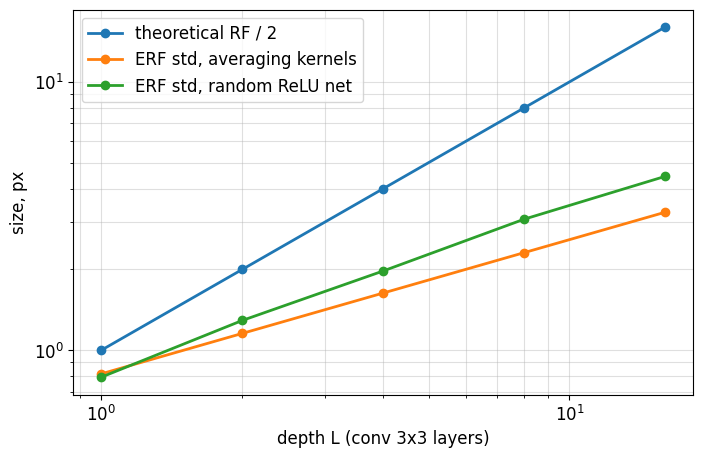

In [17]:
plt.figure(figsize=(8, 5))
for name, values in erf.items():
    plt.loglog(depths, values, 'o-', linewidth=2, label=name)
plt.xlabel('depth L (conv 3x3 layers)')
plt.ylabel('size, px')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Как отношение эффективного RF к теоретическому меняется с глубиной (наклоны на log-log графике)? Как ведёт себя сеть с ReLU по сравнению с усредняющей?

**Ответ.** Теоретический RF растёт линейно: $r_L/2 = L$ (наклон 1 на log-log). Эффективный RF растёт как корень: для усредняющих ядер std $= 0.82, 1.15, 1.63, 2.31, 3.27$ при $L = 1, 2, 4, 8, 16$ — наклон $\log(3.27/0.82)/\log 16 \approx 0.50$, ровно $\sqrt{2L/3}$ по ЦПТ. Значит, отношение ERF/RF убывает как $L^{-1/2}$: при $L = 1$ оно ≈0.82, при $L = 16$ — лишь $3.27/16 \approx 0.20$; основная масса градиента сосредоточена в центральной части RF, а края почти не влияют.

Случайная ReLU-сеть ведёт себя качественно так же (сублинейный рост), но ERF немного шире: $0.79 \to 4.44$, наклон ≈0.62, при $L = 16$ отношение ≈0.28. Объяснение: при случайных весах разных знаков и ReLU-гейтинге $|\nabla_x y|$ — уже не свёртка одного положительного ядра, профиль менее концентрирован и имеет более тяжёлые хвосты, а усреднение модуля по входам не даёт центральным вкладам сокращаться. Ограничения: одна инициализация, 16 входов, и std профиля зависит от хвостов (на больших $L$ оценка шумнее); вывод о точном показателе для ReLU по 5 точкам ненадёжен, но качественно ERF $\ll$ RF подтверждается (как в Luo et al., 2016).

---
# 2. Нормализация

## 2.1 `BatchNorm2d` с нуля (1 балл)

В `train()`: статистики текущего батча по каналу (среднее по $b, h, w$), нормировка смещённой дисперсией и обновление буферов
$$
\hat\mu \leftarrow (1 - m)\,\hat\mu + m\, \mu_{\text{batch}}, \qquad
\hat\sigma^2 \leftarrow (1 - m)\,\hat\sigma^2 + m\, \frac{n}{n - 1}\, \sigma^2_{\text{batch}}, \qquad n = BHW,
$$
в running-дисперсию идёт несмещённая оценка. В `eval()` — нормировка по $\hat\mu, \hat\sigma^2$. Параметры `weight` ($\gamma$) и `bias` ($\beta$), буферы `running_mean`, `running_var`, `num_batches_tracked` — с теми же именами, что в `nn.BatchNorm2d`, чтобы `load_state_dict` был совместим.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [18]:
class MyBatchNorm2d(nn.Module):
    def __init__(self, num_features, eps=1e-5, momentum=0.1):
        super().__init__()
        self.eps, self.momentum = eps, momentum
        self.num_features = num_features
        self.weight = nn.Parameter(torch.ones(num_features))     # gamma
        self.bias = nn.Parameter(torch.zeros(num_features))      # beta
        self.register_buffer('running_mean', torch.zeros(num_features))
        self.register_buffer('running_var', torch.ones(num_features))
        self.register_buffer('num_batches_tracked', torch.tensor(0, dtype=torch.long))

    def forward(self, x):
        if self.training:
            mean = x.mean(dim=(0, 2, 3))
            var = x.var(dim=(0, 2, 3), unbiased=False)          # смещённая дисперсия для нормировки батча
            n = x.numel() / x.shape[1]                          # n = B * H * W
            with torch.no_grad():
                m = self.momentum
                self.running_mean.mul_(1 - m).add_(m * mean)
                self.running_var.mul_(1 - m).add_(m * var * n / (n - 1))   # несмещённая оценка в буфер
                self.num_batches_tracked += 1
        else:
            mean, var = self.running_mean, self.running_var
        x_hat = (x - mean[None, :, None, None]) / torch.sqrt(var[None, :, None, None] + self.eps)
        return x_hat * self.weight[None, :, None, None] + self.bias[None, :, None, None]


In [19]:
torch.manual_seed(0)
mine, ref = MyBatchNorm2d(8), nn.BatchNorm2d(8)
assert set(dict(mine.named_parameters())) == {'weight', 'bias'}
assert set(dict(mine.named_buffers())) == {'running_mean', 'running_var', 'num_batches_tracked'}
with torch.no_grad():
    for m in (mine, ref):
        m.weight.copy_(torch.linspace(0.5, 2, 8))
        m.bias.copy_(torch.linspace(-1, 1, 8))

for step in range(10):
    x = (torch.randn(4, 8, 5, 5) * 3 + 2).requires_grad_(True)
    out_mine, out_ref = mine(x), ref(x)
    assert torch.allclose(out_mine, out_ref, atol=1e-5), step
    g = torch.randn_like(out_ref)
    grads_mine = torch.autograd.grad(out_mine, (x, mine.weight, mine.bias), g)
    grads_ref = torch.autograd.grad(out_ref, (x, ref.weight, ref.bias), g)
    assert all(torch.allclose(a, b, atol=1e-4) for a, b in zip(grads_mine, grads_ref)), step

for name, buf in ref.named_buffers():
    assert torch.allclose(getattr(mine, name).float(), buf.float(), atol=1e-5), name

mine.eval(), ref.eval()
x = torch.randn(4, 8, 5, 5)
assert torch.allclose(mine(x), ref(x), atol=1e-5)
mine.load_state_dict(ref.state_dict())

<All keys matched successfully>

**Вопрос.** Почему в running-дисперсию идёт несмещённая оценка, а в нормировку батча — смещённая? Насколько они различаются при $B = 4$ и карте $5 \times 5$, и при $B = 2$ и карте $1 \times 1$?

**Ответ.** В нормировке батча BN — детерминированное преобразование, которое должно сделать **именно этот батч** центрированным и с единичной дисперсией; это ровно смещённая (выборочная, делённая на $n$) дисперсия, и именно её использует `nn.BatchNorm2d` (иначе тест с `atol=1e-5` не прошёл бы). Running-статистики — оценки параметров **генеральной совокупности**, которые применяются в `eval()` к новым данным; для дисперсии генеральной совокупности несмещённая оценка $\frac{n}{n-1}\sigma^2_{\text{batch}}$ даёт $\mathbb E = \sigma^2$, а смещённая систематически её занижает.

Разница — множитель $\frac{n}{n-1}$:

- $B = 4$, карта $5\times5$: $n = 100$, множитель $100/99 \approx 1.0101$ — расхождение ≈1%, практически несущественно;
- $B = 2$, карта $1\times1$: $n = 2$, множитель $2$ — смещённая дисперсия занижена вдвое (а нормированные значения в train вырождаются в $\pm 1$). Здесь train- и eval-поведение сильно различаются, поэтому BN при крошечных батчах и картах работает плохо.

## 2.2 Слияние свёртки и BatchNorm для инференса (1 балл)

В `eval()` BN — поканальное аффинное преобразование с фиксированными $\hat\mu, \hat\sigma^2$, поэтому $\mathrm{BN}(\mathrm{conv}(x))$ — снова свёртка с другими весами $W'$ и bias $b'$.

1. Выведите $W'$ и $b'$ в ячейке «Ответ» ниже.
2. Реализуйте `fuse_conv_bn(conv, bn)`, возвращающую новую `nn.Conv2d`: сохраняются `dtype`, `device`, `padding_mode`, `groups`, stride, padding и dilation; bias у исходной свёртки может отсутствовать. Входные модули в `eval()`, BN с affine и running statistics; исходные веса не менять.
3. Реализуйте `fuse_sequential(seq)` для плоского `nn.Sequential` в `eval()`: каждую соседнюю пару `Conv2d, BatchNorm2d` заменить свёрткой. Остальные модули скопировать через `copy.deepcopy`, исходную сеть не менять; рекурсивный обход вложенных контейнеров не требуется.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

**Ответ.** В `eval()` для выходного канала $o$: $\mathrm{BN}(u)_o = \gamma_o \frac{u_o - \hat\mu_o}{\sqrt{\hat\sigma_o^2 + \epsilon}} + \beta_o$, а $u_o = (W_o * x) + b_o$ (если bias у свёртки нет, $b_o = 0$). Обозначим $s_o = \gamma_o / \sqrt{\hat\sigma_o^2 + \epsilon}$. Тогда
$$
\mathrm{BN}(\mathrm{conv}(x))_o = s_o (W_o * x) + s_o (b_o - \hat\mu_o) + \beta_o,
$$
то есть это свёртка с теми же stride/padding/dilation/groups и
$$
W'_o = s_o\, W_o \quad (\text{масштабируется весь срез } W[o, :, :, :]), \qquad b'_o = \beta_o + s_o\,(b_o - \hat\mu_o).
$$
С `groups` формула та же: каждый выходной канал принадлежит ровно одной группе, а $s_o$ — поканальный множитель. `padding_mode='reflect'` тоже сохраняется, потому что BN действует после паддинга и свёртки, поканально.

In [20]:
@torch.no_grad()
def fuse_conv_bn(conv, bn):
    fused = nn.Conv2d(conv.in_channels, conv.out_channels, conv.kernel_size, stride=conv.stride,
                      padding=conv.padding, dilation=conv.dilation, groups=conv.groups, bias=True,
                      padding_mode=conv.padding_mode, device=conv.weight.device, dtype=conv.weight.dtype)
    scale = bn.weight / torch.sqrt(bn.running_var + bn.eps)          # gamma / sqrt(var + eps), по каналам
    fused.weight.copy_(conv.weight * scale.view(-1, 1, 1, 1))        # W' = W * scale
    b = conv.bias if conv.bias is not None else torch.zeros_like(bn.running_mean)
    fused.bias.copy_(bn.bias + (b - bn.running_mean) * scale)        # b' = beta + (b - mu) * scale
    return fused.eval()


def fuse_sequential(seq):
    mods = list(seq)
    fused, i = [], 0
    while i < len(mods):
        if isinstance(mods[i], nn.Conv2d) and i + 1 < len(mods) and isinstance(mods[i + 1], nn.BatchNorm2d):
            fused.append(fuse_conv_bn(mods[i], mods[i + 1]))
            i += 2
        else:
            fused.append(copy.deepcopy(mods[i]))
            i += 1
    return nn.Sequential(*fused)


In [21]:
torch.manual_seed(0)
for cfg in [dict(bias=True), dict(bias=False), dict(groups=4), dict(stride=2, padding=1, dilation=2)]:
    conv, bn = nn.Conv2d(8, 16, 3, **cfg), nn.BatchNorm2d(16)
    with torch.no_grad():
        bn.weight.uniform_(0.5, 2)
        bn.bias.uniform_(-1, 1)
        for _ in range(5):
            bn(conv(torch.randn(8, 8, 12, 12) * 2 + 1))   # накопить running-статистики
    conv.eval(), bn.eval()
    x = torch.randn(4, 8, 12, 12)
    fused = fuse_conv_bn(conv, bn)
    assert isinstance(fused, nn.Conv2d)
    assert torch.allclose(fused(x), bn(conv(x)), atol=1e-5), cfg

conv = nn.Conv2d(4, 8, 3, padding=1, padding_mode='reflect', groups=2, bias=False).double().eval()
bn = nn.BatchNorm2d(8).double().eval()
x = torch.randn(2, 4, 9, 11, dtype=torch.float64)
fused = fuse_conv_bn(conv, bn)
assert fused.weight.dtype == x.dtype and fused.padding_mode == 'reflect'
assert torch.allclose(fused(x), bn(conv(x)), atol=1e-10, rtol=1e-10)

In [22]:
def make_vgg_like(width=64, n_blocks=6):
    layers, c = [], 3
    for i in range(n_blocks):
        layers += [nn.Conv2d(c, width, 3, padding=1, bias=False), nn.BatchNorm2d(width), nn.ReLU()]
        c = width
        if i % 2 == 1:
            layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(width, 10))


torch.manual_seed(0)
vgg = make_vgg_like()
with torch.no_grad():
    for _ in range(5):
        vgg(torch.randn(32, 3, 32, 32))   # train-режим: копим статистики
vgg.eval()
vgg_fused = fuse_sequential(vgg).eval()
x = torch.randn(64, 3, 32, 32)
assert not any(isinstance(m, nn.BatchNorm2d) for m in vgg_fused.modules())
assert torch.allclose(vgg(x), vgg_fused(x), atol=1e-4)

In [23]:
with torch.inference_mode():
    t_bn = min(timeit.repeat(lambda: vgg(x), number=5, repeat=5)) / 5
    t_fused = min(timeit.repeat(lambda: vgg_fused(x), number=5, repeat=5)) / 5
print(f'Conv + BN: {t_bn * 1000:.1f} ms   fused: {t_fused * 1000:.1f} ms   speedup {t_bn / t_fused:.2f}x')

Conv + BN: 140.4 ms   fused: 136.6 ms   speedup 1.03x


**Вопрос.** Почему слияние корректно только в `eval()`? Что даёт слияние и от чего зависит выигрыш?

**Ответ.** Слияние корректно только в `eval()`, потому что лишь там BN — фиксированное аффинное преобразование с константами $\hat\mu, \hat\sigma^2$. В `train()` BN нормирует статистиками текущего батча: $\mu_{\text{batch}}$ и $\sigma^2_{\text{batch}}$ зависят от входа, то есть результат для одного объекта зависит от других объектов батча — это не свёртка, и никакие фиксированные $W', b'$ его не воспроизводят; кроме того, в train BN обновляет running-буферы и пропускает градиент через статистики батча.

Слияние убирает отдельный проход по активациям: BN почти не считает, но читает и пишет весь тензор (memory-bound), плюс отдельный вызов ядра. В финальном прогоне (Colab; эта ячейка считается на CPU виртуальной машины — 2 vCPU) VGG-подобная сеть с батчем 64: 140.4 ms → 136.6 ms, ускорение всего ≈1.03×; в отладочном прогоне на моём 16-ядерном CPU было 32.5 → 24.3 ms (≈1.34×). Результат совпадает с точностью `atol=1e-4`. Выигрыш зависит от доли BN во времени: он больше, когда свёртки дешёвые относительно объёма активаций (мало каналов, depthwise-свёртки, маленький батч, CPU/мобильные устройства), и меньше для тяжёлых свёрток; также от того, умеет ли бэкенд сам сливать операции (TensorRT, `torch.compile`, oneDNN post-ops), и от шума измерения. Разница 1.03× vs 1.34× на двух машинах хорошо это иллюстрирует: на слабом CPU время доминирует свёрткой, и экономия одного прохода BN почти незаметна.

---
# 3. Инициализация и оптимизатор

## 3.1 Дисперсия активаций по глубине (1 балл)

Слой $h = W z$, $W_{ij}$ независимы, $\mathbb E W_{ij} = 0$, $\mathrm{Var}\, W_{ij} = v$, $W$ не зависит от $z \in \mathbb R^{n}$:
$$
\mathrm{Var}(h_i) = n\, v\; \mathbb E\big[z_j^2\big].
$$

1. В ячейке «Ответ» ниже выведите $v$, при котором $\mathrm{Var}(h)$ не меняется от слоя к слою, для $z = \mathrm{ReLU}(h^{\text{prev}})$ с симметричным $h^{\text{prev}}$ и для $\tanh$ в линейном режиме. Инициализация `nn.Linear` по умолчанию — $\mathcal U(-1/\sqrt n,\, 1/\sqrt n)$: во сколько раз за слой меняется стандартное отклонение активаций для ReLU?
2. Реализуйте `activation_stds`: MLP глубины 50 и ширины 256 без bias, на входе $\mathcal N(0, I)$, вернуть `h.std().item()` после каждой активации — по **всем** элементам тензора `(n, width)`, а не среднее std по отдельным нейронам. Верните список из `depth` чисел.

**Оценивание:** код — 0.3; эксперимент — 0.3; объяснение — 0.4 балла.

**Ответ.** Из $\mathrm{Var}(h_i) = n v\, \mathbb E[z_j^2]$ требуем $\mathrm{Var}(h) = \mathrm{Var}(h^{\text{prev}})$.

- **ReLU**, $z = \max(0, h^{\text{prev}})$ с симметричным $h^{\text{prev}}$: половина массы обнуляется, $\mathbb E[z^2] = \tfrac12 \mathbb E[(h^{\text{prev}})^2] = \tfrac12 \mathrm{Var}(h^{\text{prev}})$. Тогда $\mathrm{Var}(h) = \tfrac{n v}{2} \mathrm{Var}(h^{\text{prev}})$, и масштаб сохраняется при $v = 2/n$ (инициализация Kaiming/He).
- **tanh в линейном режиме**: $\tanh(h) \approx h$, $\mathbb E[z^2] \approx \mathrm{Var}(h^{\text{prev}})$, поэтому $v = 1/n$ (LeCun; Xavier $\frac{2}{n_{\text{in}} + n_{\text{out}}}$ совпадает с $1/n$ для квадратных слоёв).
- **PyTorch default** $\mathcal U(-1/\sqrt n, 1/\sqrt n)$: $v = \frac{(2/\sqrt n)^2}{12} = \frac{1}{3n}$. Для ReLU за слой $\mathrm{Var}$ умножается на $n \cdot \frac{1}{3n} \cdot \frac12 = \frac16$, то есть std — в $1/\sqrt6 \approx 0.408$ раза (уменьшается в ≈2.45 раза). Эксперимент даёт средний множитель 0.410.

In [24]:
INITS = {
    'N(0, 0.01^2)':    lambda w: nn.init.normal_(w, std=0.01),
    'PyTorch default': lambda w: nn.init.kaiming_uniform_(w, a=math.sqrt(5)),
    'Xavier':          nn.init.xavier_normal_,
    'Kaiming':         lambda w: nn.init.kaiming_normal_(w, nonlinearity='relu'),
}


def activation_stds(init, act, depth=50, width=256, n=1024, seed=0):
    torch.manual_seed(seed)
    h = torch.randn(n, width)
    stds = []
    with torch.no_grad():
        for _ in range(depth):
            layer = nn.Linear(width, width, bias=False)
            init(layer.weight)
            h = act(layer(h))
            stds.append(h.std().item())      # std по всем элементам тензора (n, width)
    return stds


In [25]:
stds = {(name, act_name): activation_stds(init, act)
        for name, init in INITS.items() for act_name, act in [('tanh', torch.tanh), ('ReLU', torch.relu)]}

kaiming_relu = stds['Kaiming', 'ReLU']
assert len(kaiming_relu) == 50 and np.isfinite(kaiming_relu).all()
print(f'Kaiming + ReLU, last / first std: {kaiming_relu[-1] / kaiming_relu[0]:.3f}')
default_relu = np.array(stds['PyTorch default', 'ReLU'])
rate = np.exp(np.mean(np.diff(np.log(default_relu))))   # средний множитель std за слой
assert abs(rate - 1 / math.sqrt(6)) < 0.03
rate

Kaiming + ReLU, last / first std: 0.882


np.float64(0.4100027508284732)

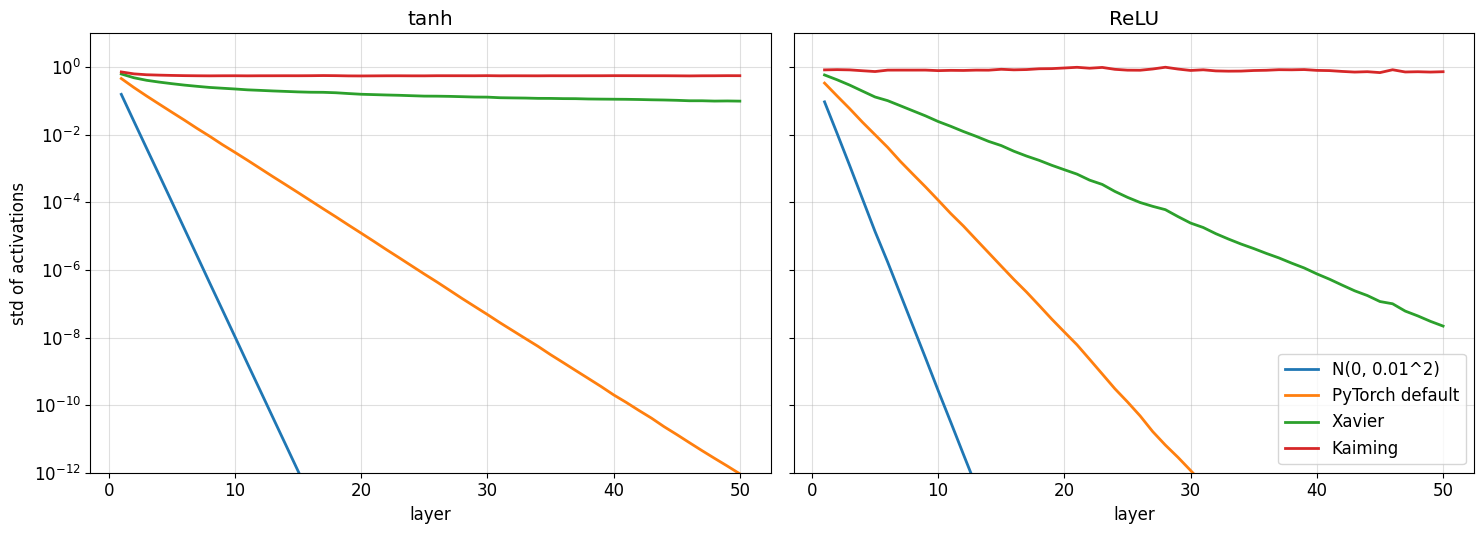

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, act_name in zip(axes, ['tanh', 'ReLU']):
    for name in INITS:
        ax.semilogy(range(1, 51), stds[name, act_name], linewidth=2, label=name)
    ax.set_title(act_name)
    ax.set_xlabel('layer')
    ax.grid(True, which='both', alpha=0.4)
axes[0].set_ylabel('std of activations')
axes[0].set_ylim(1e-12, 10)
axes[1].legend()
plt.tight_layout()
plt.show()

**Вопрос.** Какие пары (инициализация, активация) сохраняют масштаб на 50 слоях? Почему сети с инициализацией PyTorch по умолчанию всё равно обучаются (например, ResNet в задаче 4.2)?

**Ответ.** std активаций на слоях 1 → 10 → 50 (из того же прогона `activation_stds`):

| инициализация | tanh | ReLU |
|---|---|---|
| $\mathcal N(0, 0.01^2)$ | 0.157 → 1e-8 → 2e-40 | 0.094 → 3e-10 → 0 (underflow) |
| PyTorch default | 0.46 → 3e-3 → 9e-13 | 0.34 → 1.2e-4 → 4e-20 |
| Xavier | 0.63 → 0.23 → 0.099 | 0.59 → 0.025 → 2e-8 |
| Kaiming | 0.72 → 0.56 → 0.56 | 0.83 → 0.79 → 0.73 |

Масштаб на 50 слоях сохраняют **Kaiming + ReLU** (отношение последнего std к первому 0.88) и **Kaiming + tanh** (std выходит на неподвижную точку ≈0.56: усиление $\sqrt2$ компенсируется насыщением tanh). Xavier + tanh затухает медленно, не экспоненциально (до 0.1 за 50 слоёв, т.к. tanh сжимает только вне линейного режима). Остальные пары затухают экспоненциально: Xavier + ReLU — в $\sqrt2$ раз за слой, default + ReLU — в $\sqrt6$, $\mathcal N(0, 0.01^2)$ ($nv = 0.0256$) — в ≈6 раз за слой, до нуля во float32.

Сети с инициализацией по умолчанию всё равно обучаются, потому что эксперимент выше — худший случай: 50 линейных слоёв подряд без нормализации и без skip-связей. В ResNet из 4.2 после каждой свёртки стоит **BatchNorm**, который перенормирует активации к единичной дисперсии независимо от масштаба весов (выход BN инвариантен к масштабу весов предыдущей свёртки), а **residual-связи** передают сигнал по тождественному пути. К тому же глубина ResNet-20 — 20 слоёв, а Adam нормирует шаг и нечувствителен к общему масштабу градиентов. Ограничение: здесь измеряется только прямой проход при случайной инициализации; о градиентах и динамике обучения он говорит лишь косвенно.

## 3.2 `AdamW` своими руками (1.5 балла)

Шаг $t = 1, 2, \dots$; $\eta$ — learning rate, $\lambda$ — weight decay, $g_t$ — градиент:
$$
\theta \leftarrow \theta - \eta\lambda\,\theta, \qquad
m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t, \qquad
v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2,
$$
$$
\hat m_t = \frac{m_t}{1 - \beta_1^t}, \qquad \hat v_t = \frac{v_t}{1 - \beta_2^t}, \qquad
\theta \leftarrow \theta - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}.
$$
Флаг `bias_correction=False` выключает деление на $1 - \beta^t$. Гиперпараметры берутся из `group` — у разных групп параметров они могут отличаться (в `train_cifar` из задачи 4.2 weight decay не применяется к параметрам BN и bias).

**Оценивание:** код — 1.1; эксперимент — 0.1; объяснение — 0.3 балла.

In [27]:
class MyAdamW(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2, bias_correction=True):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, bias_correction=bias_correction)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            beta1, beta2 = group['betas']
            lr, wd, eps = group['lr'], group['weight_decay'], group['eps']
            for p in group['params']:
                if p.grad is None:
                    continue
                state = self.state[p]
                if len(state) == 0:
                    state['step'] = 0
                    state['exp_avg'] = torch.zeros_like(p)
                    state['exp_avg_sq'] = torch.zeros_like(p)
                state['step'] += 1
                t = state['step']
                g = p.grad
                m, v = state['exp_avg'], state['exp_avg_sq']
                p.mul_(1 - lr * wd)                              # decoupled weight decay
                m.mul_(beta1).add_(g, alpha=1 - beta1)
                v.mul_(beta2).addcmul_(g, g, value=1 - beta2)
                if group['bias_correction']:
                    m_hat = m / (1 - beta1 ** t)
                    v_hat = v / (1 - beta2 ** t)
                else:
                    m_hat, v_hat = m, v
                p.addcdiv_(m_hat, v_hat.sqrt().add_(eps), value=-lr)


In [28]:
def final_params(make_optimizer, steps=100):
    torch.manual_seed(0)
    model = nn.Sequential(nn.Linear(10, 32), nn.Tanh(), nn.Linear(32, 1))
    optimizer = make_optimizer(model)
    gen = torch.Generator().manual_seed(1)
    for _ in range(steps):
        x = torch.randn(64, 10, generator=gen)
        loss = F.mse_loss(model(x), x[:, :1] ** 2)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return torch.cat([p.detach().flatten() for p in model.parameters()])


def param_groups(model, wd):
    return [dict(params=[p for p in model.parameters() if p.ndim > 1], weight_decay=wd),
            dict(params=[p for p in model.parameters() if p.ndim <= 1], weight_decay=0.0, lr=3e-3)]


for kwargs in [dict(lr=1e-2), dict(lr=1e-2, weight_decay=0.1), dict(lr=3e-3, betas=(0.8, 0.9), eps=1e-1)]:
    mine = final_params(lambda m: MyAdamW(m.parameters(), **kwargs))
    ref = final_params(lambda m: torch.optim.AdamW(m.parameters(), **kwargs))
    assert torch.allclose(mine, ref, atol=1e-5), kwargs
mine = final_params(lambda m: MyAdamW(param_groups(m, 0.1), lr=1e-2))
ref = final_params(lambda m: torch.optim.AdamW(param_groups(m, 0.1), lr=1e-2))
assert torch.allclose(mine, ref, atol=1e-5)

Длина шага при постоянном градиенте $g = 1$:

In [29]:
def step_lengths(make_optimizer, steps=1000):
    p = torch.zeros(1, requires_grad=True)
    optimizer = make_optimizer([p])
    lengths = []
    for _ in range(steps):
        before = p.item()
        optimizer.zero_grad()
        p.sum().backward()
        optimizer.step()
        lengths.append(before - p.item())
    return np.array(lengths)


lr = 0.01
bc_runs = {bc: step_lengths(lambda ps: MyAdamW(ps, lr=lr, weight_decay=0, bias_correction=bc)) for bc in [True, False]}
for bc, lengths in bc_runs.items():
    ratio = np.round(lengths / lr, 4)
    print(f'bias_correction={bc!s:<5}  step / lr: ' + '  '.join(f't={t}: {ratio[t - 1]:.2f}' for t in [1, 10, 100, 1000])
          + f'   max {ratio.max():.2f} at t={ratio.argmax() + 1}')

bias_correction=True   step / lr: t=1: 1.00  t=10: 1.00  t=100: 1.00  t=1000: 1.00   max 1.00 at t=1
bias_correction=False  step / lr: t=1: 3.16  t=10: 6.53  t=100: 3.24  t=1000: 1.26   max 6.57 at t=12


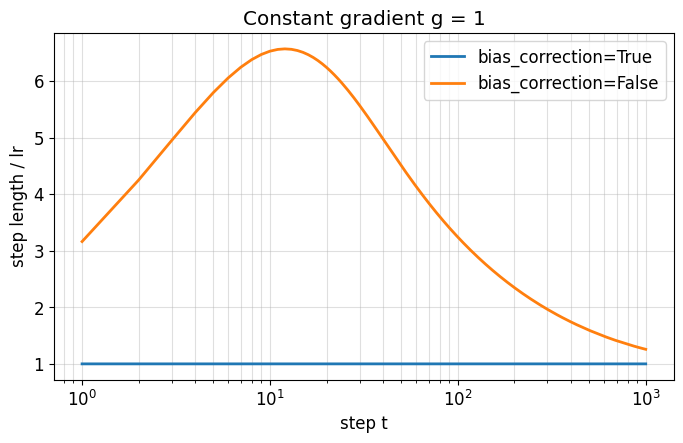

In [30]:
plt.figure(figsize=(8, 4.5))
for bc, lengths in bc_runs.items():
    plt.semilogx(range(1, len(lengths) + 1), lengths / lr, linewidth=2, label=f'bias_correction={bc}')
plt.xlabel('step t')
plt.ylabel('step length / lr')
plt.title('Constant gradient g = 1')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Выведите длину шага без bias correction при $g_t \equiv 1$ как функцию $t$ и сравните с выводом ячейки. Чем это опасно в начале обучения?

**Ответ.** При $g_t \equiv 1$ и $m_0 = v_0 = 0$: $m_t = (1-\beta_1)\sum_{i<t}\beta_1^i = 1 - \beta_1^t$, аналогично $v_t = 1 - \beta_2^t$. Без bias correction (при $\lambda = 0$)
$$
\frac{\text{step}_t}{\eta} = \frac{1 - \beta_1^t}{\sqrt{1 - \beta_2^t} + \epsilon} \approx \frac{1 - 0.9^t}{\sqrt{1 - 0.999^t}}.
$$
Подстановка: $t = 1$: $0.1/\sqrt{0.001} = 3.16$; $t = 10$: $0.651/\sqrt{0.00995} = 6.53$; $t = 100$: $0.99997/\sqrt{0.0952} = 3.24$; $t = 1000$: $1/\sqrt{0.632} = 1.26$; максимум ≈6.57 при $t \approx 12$ — в точности как в выводе ячейки. При $t \to \infty$ отношение → 1. С bias correction $\hat m_t = \hat v_t = 1$ и шаг ровно $\eta$ на каждом шаге (вывод 1.00).

Опасность: $v_t$ «прогревается» намного медленнее ($1 - \beta_2 = 10^{-3}$, характерное время ~1000 шагов), чем $m_t$ (~10 шагов), поэтому знаменатель занижен и в первые сотни шагов эффективный шаг в 3–6.6 раза больше заданного lr. Именно в начале обучения веса случайны, градиенты большие и loss-ландшафт острый, и такой «анти-warmup» может привести к взрыву loss, расхождению или порче статистик BN; lr, подобранный для установившегося режима, оказывается слишком большим на старте.

## 3.3 Cosine schedule (0.5 балла)

Множитель learning rate для `LambdaLR` (шаг $t$ считается с нуля, $T$ — число шагов, $r$ — доля от начального lr в конце):
$$
\lambda(t) = r + (1 - r)\, \frac{1 + \cos\big(\pi \min(1,\, t / T)\big)}{2}.
$$
На интервале от нулевого шага до $T$ это то же расписание, что `CosineAnnealingLR(T_max=T, eta_min=r·lr)`; после $T$ наша функция остаётся на минимуме, в отличие от продолжения cosine в PyTorch; проверка — совпадение learning rate по шагам с вашим `MyAdamW`.

**Оценивание:** код — 0.3; эксперимент — 0; объяснение — 0.2 балла.

In [31]:
def cosine_lr(step, total_steps, min_ratio=0.0):
    progress = min(1.0, step / total_steps)
    return min_ratio + (1 - min_ratio) * (1 + math.cos(math.pi * progress)) / 2


In [32]:
T, r, base_lr = 500, 0.1, 3e-3
lam = [cosine_lr(t, T, r) for t in range(T + 1)]
assert abs(lam[0] - 1) < 1e-12 and abs(lam[T] - r) < 1e-12 and abs(cosine_lr(2 * T, T, r) - r) < 1e-12
assert abs(lam[T // 2] - (r + (1 - r) / 2)) < 1e-9


def lr_trace(make_scheduler, steps=T):
    p = torch.zeros(1, requires_grad=True)
    optimizer = MyAdamW([p], lr=base_lr)
    scheduler = make_scheduler(optimizer)
    trace = []
    for _ in range(steps):
        trace.append(scheduler.get_last_lr()[0])
        optimizer.step()
        scheduler.step()
    return np.array(trace)


mine = lr_trace(lambda opt: torch.optim.lr_scheduler.LambdaLR(opt, lambda t: cosine_lr(t, T, r)))
ref = lr_trace(lambda opt: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=T, eta_min=r * base_lr))
assert np.allclose(mine, ref, rtol=1e-6, atol=1e-12)

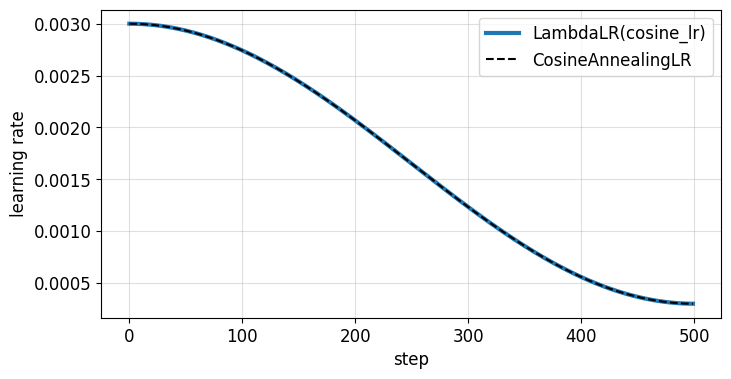

In [33]:
plt.figure(figsize=(8, 4))
plt.plot(mine, linewidth=3, label='LambdaLR(cosine_lr)')
plt.plot(ref, 'k--', linewidth=1.5, label='CosineAnnealingLR')
plt.xlabel('step')
plt.ylabel('learning rate')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Зачем уменьшать learning rate к концу обучения, если оптимизатор и так адаптивный? Что происходит со стохастическим методом при постоянном шаге около минимума?

**Ответ.** Адаптивность Adam/AdamW нормирует шаг по координатам ($m/\sqrt{v}$), но не делает его малым около минимума: у стохастического градиента $g = \nabla L + \xi$ около минимума $\nabla L \approx 0$, а шум $\xi$ остаётся, и $\sqrt{v}$ тоже определяется шумом, поэтому отношение $m/\sqrt v$ имеет порядок $O(1)$ (или $\sim\sqrt{1-\beta_1}$), а шаг — порядок $\eta$. При постоянном шаге стохастический метод не сходится к точке: итерации блуждают в окрестности минимума («noise ball»), размер которой и избыточный loss растут с $\eta$ (для SGD стационарная дисперсия $\propto \eta \cdot \mathrm{Var}(\xi)$). Уменьшение lr к концу обучения сжимает эту окрестность и усредняет шум — обычно это даёт заметное падение train loss и рост accuracy на последних эпохах (это видно и в 4.2). Большой lr в начале при этом полезен для быстрого прогресса и исследования ландшафта. Наш `LambdaLR(cosine_lr)` совпал с `CosineAnnealingLR` по всем шагам (`np.allclose`), а после $T$ остаётся на $r\cdot\eta$, в отличие от периодического продолжения в PyTorch.

---
# 4. ResNet на CIFAR-10

CIFAR-10: 50 000 + 10 000 цветных картинок $32 \times 32$, 10 классов. Весь датасет хранится одним `uint8`-тензором на `device` (≈ 180 MB), нормализация делается на лету над батчем.

In [34]:
N_TRAIN = 10_000 if FAST_MODE else 50_000
N_TEST = 2_000 if FAST_MODE else 10_000

cifar_train = datasets.CIFAR10(DATA_ROOT, train=True, download=True)
cifar_test = datasets.CIFAR10(DATA_ROOT, train=False, download=True)
CIFAR_CLASSES = cifar_train.classes


def to_tensors(ds, n):
    X = torch.from_numpy(ds.data[:n]).permute(0, 3, 1, 2).contiguous()   # uint8 (N, 3, 32, 32)
    return X.to(device), torch.tensor(ds.targets[:n]).to(device)


X_train, Y_train = to_tensors(cifar_train, N_TRAIN)
X_test, Y_test = to_tensors(cifar_test, N_TEST)
CIFAR_MEAN = (X_train.float() / 255).mean(dim=(0, 2, 3))
CIFAR_STD = (X_train.float() / 255).std(dim=(0, 2, 3))
X_train.shape, X_test.shape, CIFAR_MEAN, CIFAR_STD

100%|██████████| 170M/170M [15:41<00:00, 181kB/s]


(torch.Size([50000, 3, 32, 32]),
 torch.Size([10000, 3, 32, 32]),
 tensor([0.4914, 0.4822, 0.4465], device='cuda:0'),
 tensor([0.2470, 0.2435, 0.2616], device='cuda:0'))

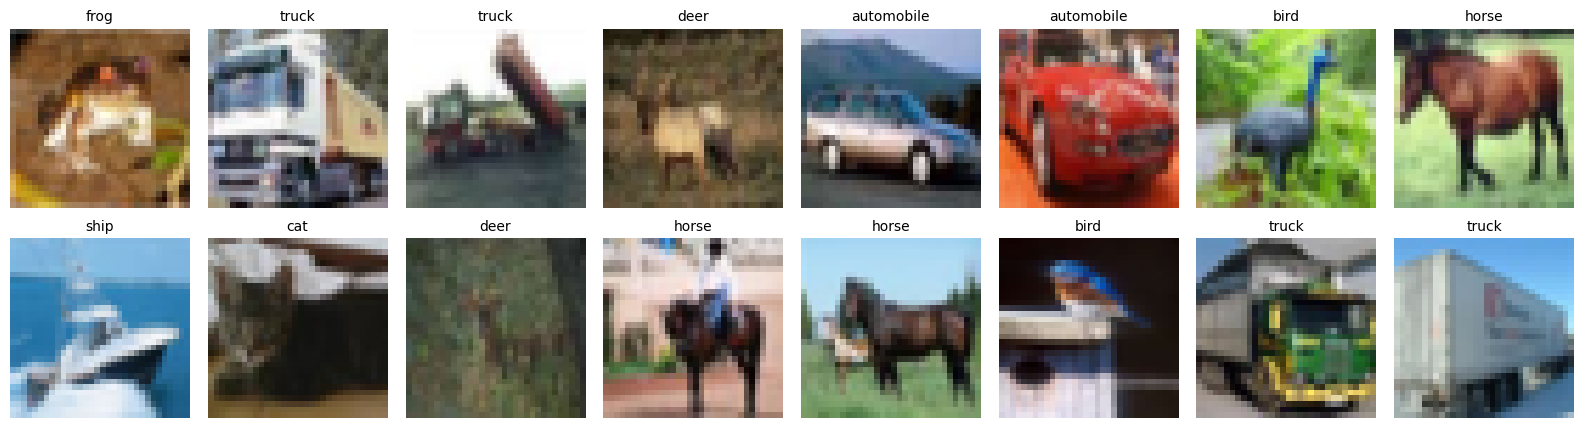

In [35]:
def normalize(x_uint8):
    return (x_uint8.float() / 255 - CIFAR_MEAN[:, None, None]) / CIFAR_STD[:, None, None]


fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(X_train[i].permute(1, 2, 0).cpu())
    ax.set_title(CIFAR_CLASSES[Y_train[i]], fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4.1 ResNet для CIFAR (1 балл)

ResNet для CIFAR из §4.2 статьи [Deep Residual Learning for Image Recognition](https://arxiv.org/pdf/1512.03385), He et al., 2015: stem — свёртка $3 \times 3$ на 16 каналов с BN и ReLU; затем три стадии по $n$ блоков шириной 16, 32 и 64; в конце global average pooling и `Linear(64, 10)`. Глубина $6n + 2$. Первый блок второй и третьей стадии — со stride 2.

Блок (свёртки $3 \times 3$ без bias):
$$
F(x) = \mathrm{BN}\Big(\mathrm{Conv}\big(\mathrm{ReLU}(\mathrm{BN}(\mathrm{Conv}(x)))\big)\Big), \qquad y = \mathrm{ReLU}\big(F(x) + \mathrm{shortcut}(x)\big).
$$
Shortcut — `Identity`, а при смене формы (stride 2 или другое число каналов) — свёртка $1 \times 1$ с тем же stride и BN после неё. Флаги:

- `residual=False` — plain-сеть: сложения нет, shortcut-модулей нет;
- `separable=True` — каждая $3 \times 3$ свёртка блоков заменена на depthwise $3 \times 3$ и следующую за ней pointwise $1 \times 1$, обе без bias; stem остаётся обычным.

**Оценивание:** код — 1; эксперимент — 0; объяснение — 0 балла.

In [36]:
def conv3x3(c_in, c_out, stride=1, separable=False):
    if separable:
        # depthwise 3x3 + pointwise 1x1, обе без bias
        return nn.Sequential(nn.Conv2d(c_in, c_in, 3, stride=stride, padding=1, groups=c_in, bias=False),
                             nn.Conv2d(c_in, c_out, 1, bias=False))
    return nn.Conv2d(c_in, c_out, 3, stride=stride, padding=1, bias=False)


class Block(nn.Module):
    def __init__(self, c_in, c_out, stride=1, residual=True, separable=False):
        super().__init__()
        self.residual = residual
        self.conv1 = conv3x3(c_in, c_out, stride, separable)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = conv3x3(c_out, c_out, 1, separable)
        self.bn2 = nn.BatchNorm2d(c_out)
        if residual:
            if stride != 1 or c_in != c_out:
                self.shortcut = nn.Sequential(nn.Conv2d(c_in, c_out, 1, stride=stride, bias=False),
                                              nn.BatchNorm2d(c_out))
            else:
                self.shortcut = nn.Identity()

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + self.shortcut(x)
        return F.relu(out)


class ResNetCIFAR(nn.Module):
    def __init__(self, depth=20, residual=True, separable=False, widths=(16, 32, 64), n_classes=10):
        super().__init__()
        assert (depth - 2) % 6 == 0
        n = (depth - 2) // 6
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, padding=1, bias=False),
                                  nn.BatchNorm2d(widths[0]), nn.ReLU())
        blocks, c = [], widths[0]
        for i, w in enumerate(widths):
            for j in range(n):
                stride = 2 if (i > 0 and j == 0) else 1    # первый блок 2-й и 3-й стадии — stride 2
                blocks.append(Block(c, w, stride, residual, separable))
                c = w
        self.blocks = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(c, n_classes)

    def forward(self, x):
        x = self.blocks(self.stem(x))
        return self.fc(self.pool(x).flatten(1))


In [37]:
x = torch.randn(2, 3, 32, 32)
for depth in [8, 20, 56]:
    for kwargs in [dict(), dict(residual=False), dict(separable=True)]:
        assert ResNetCIFAR(depth, **kwargs)(x).shape == (2, 10), (depth, kwargs)
assert n_params(ResNetCIFAR(20)) == 272_474
assert n_params(ResNetCIFAR(20, residual=False)) == 269_722
{name: n_params(ResNetCIFAR(depth, **kwargs)) for name, depth, kwargs in
 [('ResNet-20', 20, {}), ('ResNet-56', 56, {}), ('ResNet-20, separable', 20, dict(separable=True))]}

{'ResNet-20': 272474, 'ResNet-56': 855770, 'ResNet-20, separable': 40522}

## 4.2 Обучение (2 балла)

Реализуйте `train_cifar`: `MyAdamW` из 3.2 (weight decay только для параметров с `ndim > 1`), `LambdaLR` с `cosine_lr` из 3.3 до нуля за всё обучение ($r = 0$), cross-entropy, батч 256. После каждой эпохи — test accuracy. Вернуть историю `dict(train_loss, test_acc)` по эпохам.

Для ResNet-20 при `FAST_MODE = False` ориентир test accuracy — `TARGET_ACC` за `EPOCHS` эпох с `LR`. Это диагностический ориентир, не жёсткий порог балла: при заметном отставании проверьте normalisation, train/eval, scheduler и loss и опишите результат. Аугментации в этом протоколе нет. Каждый батч нормируйте через `normalize`; `scheduler.step()` вызывается после каждого `optimizer.step()`, `train_loss` — среднее по объектам за эпоху.

Test используется для учебных кривых с заранее фиксированными гиперпараметрами. Если выбираете гиперпараметры самостоятельно, выделите validation из train; test не используйте для выбора конфигурации.

**Оценивание:** код — 1.1; эксперимент — 0.6; объяснение — 0.3 балла.

In [38]:
EPOCHS = 3 if FAST_MODE else 20
LR = 0.003
TARGET_ACC = 0.82


def train_cifar(model, epochs, lr, weight_decay=0.05, batch_size=256, log=True):
    model = model.to(device)
    history = dict(train_loss=[], test_acc=[])
    start = time.time()
    decay = [p for p in model.parameters() if p.ndim > 1]        # веса conv / linear
    no_decay = [p for p in model.parameters() if p.ndim <= 1]    # BN и bias — без weight decay
    optimizer = MyAdamW([dict(params=decay, weight_decay=weight_decay),
                         dict(params=no_decay, weight_decay=0.0)], lr=lr)
    total_steps = epochs * math.ceil(len(X_train) / batch_size)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda t: cosine_lr(t, total_steps, 0.0))
    for epoch in range(epochs):
        model.train()
        loss_sum, n_seen = 0.0, 0
        for xb, yb in iterate_batches(X_train, Y_train, batch_size, shuffle=True, transform=normalize):
            loss = F.cross_entropy(model(xb), yb)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            scheduler.step()
            loss_sum += loss.item() * len(yb)
            n_seen += len(yb)
        history['train_loss'].append(loss_sum / n_seen)
        history['test_acc'].append(accuracy(predict_logits(model, X_test, transform=normalize), Y_test))
        if log:
            print(f'epoch {epoch + 1:>3}/{epochs}  train loss {history["train_loss"][-1]:.4f}  '
                  f'test acc {history["test_acc"][-1]:.4f}  lr {scheduler.get_last_lr()[0]:.2e}  '
                  f'{time.time() - start:.0f}s')
    return history


In [39]:
set_seed(0)
resnet20 = ResNetCIFAR(20)
started = time.perf_counter()
history = train_cifar(resnet20, EPOCHS, LR)
RUN_TIMES['cifar_resnet20_seconds'] = time.perf_counter() - started
history_cifar = history
test_acc = history['test_acc'][-1]
train_acc = accuracy(predict_logits(resnet20, X_train[:10_000], transform=normalize), Y_train[:10_000])
if not FAST_MODE and test_acc < TARGET_ACC:
    print(f'Accuracy {test_acc:.3f} ниже ориентира {TARGET_ACC:.2f}: проверьте протокол и обсудите результат.')
{'train acc': train_acc, 'test acc': test_acc}

epoch   1/20  train loss 1.4307  test acc 0.5382  lr 2.98e-03  18s
epoch   2/20  train loss 0.9500  test acc 0.5992  lr 2.93e-03  34s
epoch   3/20  train loss 0.7600  test acc 0.6606  lr 2.84e-03  50s
epoch   4/20  train loss 0.6431  test acc 0.6990  lr 2.71e-03  67s
epoch   5/20  train loss 0.5621  test acc 0.7475  lr 2.56e-03  85s
epoch   6/20  train loss 0.4883  test acc 0.7582  lr 2.38e-03  103s
epoch   7/20  train loss 0.4277  test acc 0.7903  lr 2.18e-03  123s
epoch   8/20  train loss 0.3712  test acc 0.7361  lr 1.96e-03  143s
epoch   9/20  train loss 0.3183  test acc 0.7880  lr 1.73e-03  162s
epoch  10/20  train loss 0.2608  test acc 0.8142  lr 1.50e-03  180s
epoch  11/20  train loss 0.2093  test acc 0.8023  lr 1.27e-03  200s
epoch  12/20  train loss 0.1611  test acc 0.8174  lr 1.04e-03  219s
epoch  13/20  train loss 0.1085  test acc 0.8197  lr 8.19e-04  238s
epoch  14/20  train loss 0.0664  test acc 0.8261  lr 6.18e-04  257s
epoch  15/20  train loss 0.0397  test acc 0.8254  lr 

{'train acc': 0.9998999834060669, 'test acc': 0.8312000036239624}

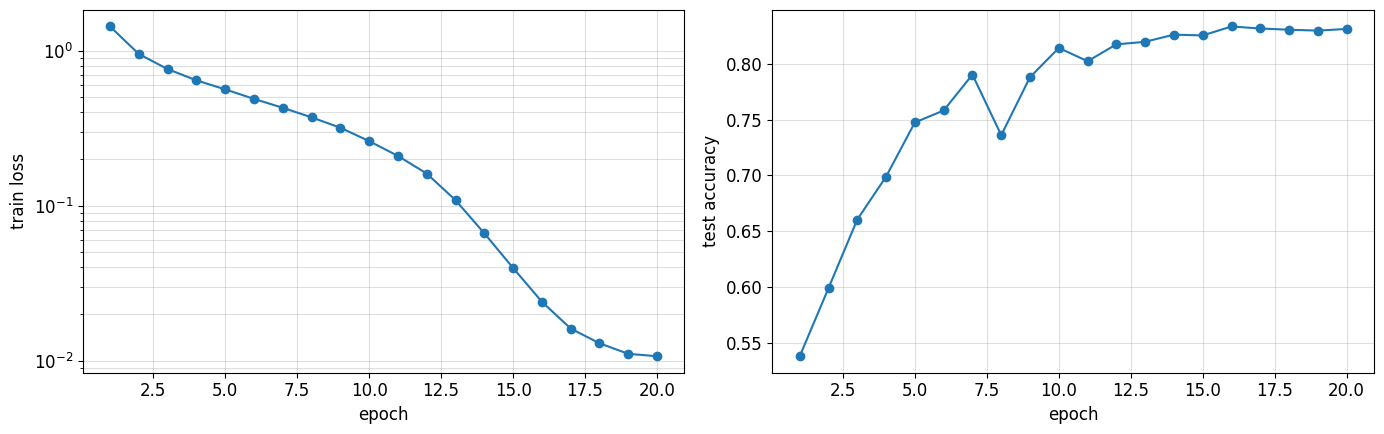

In [40]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
epochs_axis = range(1, len(history['test_acc']) + 1)
ax1.semilogy(epochs_axis, history['train_loss'], 'o-')
ax1.set_ylabel('train loss')
ax2.plot(epochs_axis, history['test_acc'], 'o-')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
plt.tight_layout()
plt.show()

**Вопрос.** Какой разрыв между train и test accuracy в конце обучения? Как ведут себя train loss и test accuracy на последних эпохах, когда learning rate уходит к нулю?

**Ответ.** ResNet-20, 20 эпох, `LR = 0.003`, без аугментаций (финальный прогон на T4): train accuracy на первых 10 000 объектах train **0.9999**, test accuracy **0.8312** — разрыв ≈17 п.п.; ориентир 0.82 достигнут. Train loss падает монотонно: 1.43 → 0.26 к 10-й эпохе и 0.0107 к 20-й. Test accuracy быстро растёт, но при большом lr сильно шумит: 0.54 → 0.79 к 7-й эпохе с провалами (0.790 → 0.736 на 8-й, 0.814 → 0.802 на 11-й), а с 12-й эпохи выходит на плато 0.817–0.833.

На последних эпохах, когда cosine-schedule уводит lr к нулю (6.2e-4 на 14-й эпохе → 0 на 20-й), train loss падает ещё в ≈6 раз (0.066 → 0.011), а test accuracy почти не меняется: 0.826 → 0.831 (максимум 0.833 на 16-й эпохе), колебания затухают. Малый шаг убирает шум SGD, и сеть почти идеально запоминает train; дальше обобщение ограничено переобучением без аугментаций (разрыв 17 п.п.), а не оптимизацией. Ограничения: один seed; test из 10 000 объектов имеет стандартную ошибку ≈0.4 п.п., а другие прогоны того же протокола дали 0.8271 (CPU) и 0.8213 (предыдущий запуск на T4) — разброс между запусками ~1 п.п. из-за недетерминизма GPU и порядка батчей, поэтому различия в этих пределах не значимы. Test использовался только для кривых, гиперпараметры не подбирались.

## 4.3 Абляции (1.5 балла)

Сравните **plain-20 и plain-56** при одинаковых `ABL_EPOCHS` и `LR`. Это два дополнительных обучения. Результат — `ablation[name] = dict(params, train_acc, test_acc, minutes, history)`, где `train_acc` считается на первых 10 000 объектах train, а `history` возвращается `train_cifar`.

Перед каждой конфигурацией вызовите `set_seed(0)`. Проверяем гипотезу: увеличение глубины plain-сети может затруднить оптимизацию даже на train ([He et al., 2015](https://arxiv.org/pdf/1512.03385)). Это не обещание, что при данном optimizer и коротком бюджете эффект обязательно появится. Отличайте результат «хуже на train» от «лучше на train, хуже на test». Для сравнения с residual-сетями нужен одинаковый протокол; основной ResNet-20 обучался дольше, его финальную accuracy нельзя напрямую трактовать как контроль этого опыта.

**Оценивание:** код — 0.2; эксперимент — 0.7; объяснение — 0.6 балла.

In [41]:
ABL_EPOCHS = 2 if FAST_MODE else 10
ABLATIONS = {
    'plain-20': dict(depth=20, residual=False),
    'plain-56': dict(depth=56, residual=False),
}

In [42]:
ablation = {}
for name, cfg in ABLATIONS.items():
    print(name)
    set_seed(0)
    model = ResNetCIFAR(**cfg)
    started = time.perf_counter()
    hist = train_cifar(model, ABL_EPOCHS, LR)
    minutes = (time.perf_counter() - started) / 60
    train_acc = accuracy(predict_logits(model, X_train[:10_000], transform=normalize), Y_train[:10_000])
    ablation[name] = dict(params=n_params(model), train_acc=train_acc, test_acc=hist['test_acc'][-1],
                          minutes=minutes, history=hist)
    RUN_TIMES[f'cifar_{name}_seconds'] = minutes * 60
    del model

print(f'{"model":<22}{"params":>9}{"train acc":>11}{"test acc":>10}{"minutes":>9}')
for name, res in ablation.items():
    print(f'{name:<22}{res["params"]:>9,}{res["train_acc"]:>11.4f}{res["test_acc"]:>10.4f}{res["minutes"]:>9.1f}')


plain-20
epoch   1/10  train loss 1.6706  test acc 0.3895  lr 2.93e-03  18s
epoch   2/10  train loss 1.2771  test acc 0.4643  lr 2.71e-03  36s
epoch   3/10  train loss 1.0340  test acc 0.5545  lr 2.38e-03  55s
epoch   4/10  train loss 0.8895  test acc 0.6314  lr 1.96e-03  73s
epoch   5/10  train loss 0.7748  test acc 0.7162  lr 1.50e-03  91s
epoch   6/10  train loss 0.6721  test acc 0.7439  lr 1.04e-03  110s
epoch   7/10  train loss 0.5886  test acc 0.7645  lr 6.18e-04  128s
epoch   8/10  train loss 0.5186  test acc 0.7805  lr 2.86e-04  147s
epoch   9/10  train loss 0.4644  test acc 0.7880  lr 7.34e-05  165s
epoch  10/10  train loss 0.4368  test acc 0.7907  lr 0.00e+00  183s
plain-56
epoch   1/10  train loss 1.9512  test acc 0.2082  lr 2.93e-03  56s
epoch   2/10  train loss 1.7967  test acc 0.3199  lr 2.71e-03  111s
epoch   3/10  train loss 1.6530  test acc 0.3301  lr 2.38e-03  167s
epoch   4/10  train loss 1.5385  test acc 0.3214  lr 1.96e-03  223s
epoch   5/10  train loss 1.4456  tes

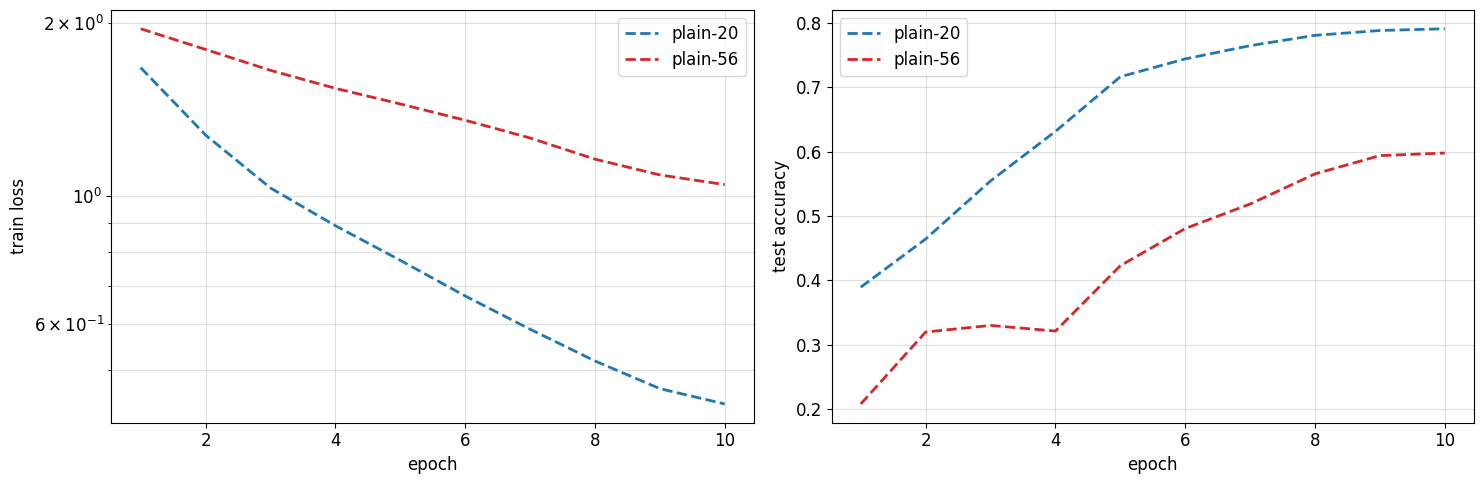

In [43]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
for name in ABLATIONS:
    hist = ablation[name]['history']
    style = '-' if name.startswith('ResNet') else '--'
    color = 'tab:blue' if '20' in name else 'tab:red'
    epochs_axis = range(1, len(hist['train_loss']) + 1)
    ax1.semilogy(epochs_axis, hist['train_loss'], style, color=color, linewidth=2, label=name)
    ax2.plot(epochs_axis, hist['test_acc'], style, color=color, linewidth=2, label=name)
ax1.set_ylabel('train loss')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
    ax.legend()
plt.tight_layout()
plt.show()

**Вопрос.** Есть ли в вашем прогоне ухудшение train loss при увеличении глубины? Как изменились train и test accuracy? Какие наблюдения говорят о трудностях оптимизации, а какие — о переобучении? Если ухудшения на train нет, напишите это. Предложите **один** следующий контрольный эксперимент, позволяющий проверить ваше объяснение; запускать его не требуется.

**Ответ.** Да, ухудшение на train есть, и это не переобучение. При одинаковом протоколе (10 эпох, `LR = 0.003`, `set_seed(0)`):

| модель | параметры | train loss (10-я эпоха) | train acc | test acc |
|---|---|---|---|---|
| plain-20 | 269 722 | 0.437 | 0.858 | 0.791 |
| plain-56 | 853 018 | 1.048 | 0.625 | 0.598 |

У plain-56 в 3.2 раза больше параметров, но train loss выше на **каждой** эпохе (1.95 vs 1.67 на первой, 1.45 vs 0.77 на пятой, 1.05 vs 0.44 в конце), а train accuracy на 23 п.п. ниже. Это признак трудностей оптимизации (degradation из He et al.): более глубокая сеть могла бы реализовать решение plain-20 (лишние слои — почти тождественные), но оптимизатор его не находит. Переобучение выглядело бы наоборот — лучше на train, хуже на test; здесь разрыв train–test у plain-56 даже меньше (2.7 п.п. против 6.7 п.п. у plain-20), т.е. глубокая сеть просто недообучена. Другие прогоны того же протокола дали ту же картину (train / test; CPU: plain-20 0.856 / 0.790, plain-56 0.676 / 0.639; предыдущий запуск на T4: 0.868 / 0.791 и 0.624 / 0.596).

Ограничения: бюджет 10 эпох короткий, и кривая plain-56 ещё круто идёт вниз — по этим данным нельзя отличить «не может обучиться» от «обучается медленнее»; один seed. **Контрольный эксперимент:** обучить ResNet-56 (`residual=True`, та же глубина и почти те же параметры) по тому же протоколу (10 эпох, тот же lr и seed). Если residual-56 на train догоняет или обгоняет plain-20, то проблема plain-56 — именно в оптимизации глубокой сети без skip-связей, а не в ёмкости или бюджете.

---
# 5. Атаки

Модель — маленькая CNN на FashionMNIST (пиксели в $[0, 1]$, без `Normalize`). В финальном режиме модель учится на полном train, а серии атак идут по фиксированным 1000 test-объектам. Раздел 5.1 обязателен; далее выполняется только ветка, выбранная в `ATTACK_TRACK`. Все модели во время оценки атак находятся в `eval()`. Метрики на такой подвыборке имеют sampling noise; близкие результаты не следует ранжировать как надёжное преимущество.

In [44]:
N_FM_TRAIN = 12_000 if FAST_MODE else 60_000
N_FM_TEST = 256 if FAST_MODE else 1_000
FM_EPOCHS = 2 if FAST_MODE else 5

fm_train = datasets.FashionMNIST(DATA_ROOT, train=True, download=True)
fm_test = datasets.FashionMNIST(DATA_ROOT, train=False, download=True)
FM_CLASSES = fm_train.classes


def fm_tensors(ds, n):
    return (ds.data[:n, None].float() / 255).to(device), ds.targets[:n].to(device)


XF_train, YF_train = fm_tensors(fm_train, N_FM_TRAIN)
XF_test, YF_test = fm_tensors(fm_test, N_FM_TEST)
XF_train.shape, XF_test.shape

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 167kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.12MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 23.5MB/s]


(torch.Size([60000, 1, 28, 28]), torch.Size([1000, 1, 28, 28]))

Модель, обучение и атаки FGSM и PGD в $L_\infty$ — готовый код:

In [45]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Linear(64 * 7 * 7, n_classes)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


def train_fm(model, epochs=FM_EPOCHS, lr=1e-3):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        model.train()
        for x, y in iterate_batches(XF_train, YF_train, 128):
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    model.eval()
    return model

In [46]:
def fgsm_attack(model, x, y, eps):
    x = x.detach()
    x_adv = x.clone().requires_grad_(True)
    with torch.enable_grad():
        grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
    return (x + eps * grad.sign()).clamp(0, 1).detach()


def pgd_attack(model, x, y, eps, alpha, steps, random_start=True):
    x = x.detach()
    x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1) if random_start else x.clone()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
    return x_adv.detach()


def pgd(model, x, y, eps, steps=20):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / steps, steps=steps)


def attack_accuracy(model, X, Y, attack=None, batch_size=500, **attack_kwargs):
    model.eval()
    correct = 0
    for i in range(0, len(X), batch_size):
        x, y = X[i:i + batch_size], Y[i:i + batch_size]
        if attack is not None:
            x = attack(model, x, y, **attack_kwargs)
        with torch.no_grad():
            correct += (model(x).argmax(dim=1) == y).sum().item()
    return correct / len(X)


def assert_no_param_grads(model):
    assert all(p.grad is None for p in model.parameters())

In [47]:
set_seed(0)
started = time.perf_counter()
model_a = train_fm(SmallCNN())
RUN_TIMES['fashion_standard_seconds'] = time.perf_counter() - started
model_a.zero_grad(set_to_none=True)
{'clean': attack_accuracy(model_a, XF_test, YF_test),
 'FGSM, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, fgsm_attack, eps=0.1),
 'PGD-20, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)}

{'clean': 0.916, 'FGSM, eps=0.1': 0.073, 'PGD-20, eps=0.1': 0.007}

## 5.1 PGD в $L_2$ (1 балл)

Ограничение $\|\delta\|_2 \le \varepsilon$. Линеаризация loss (как при выводе FGSM) даёт шаг по нормированному градиенту, а проекция на шар — масштабирование:
$$
x' = x^{(k)} + \alpha\, \frac{g}{\|g\|_2}, \qquad
\delta = x' - x, \qquad
x^{(k+1)} = \mathrm{clip}_{[0, 1]}\Big(x + \delta \cdot \min\big(1,\, \tfrac{\varepsilon}{\|\delta\|_2}\big)\Big).
$$
Нормы — по каждой картинке отдельно. Старт из $x$ (без random start).

**Оценивание:** код — 0.6; эксперимент — 0.2; объяснение — 0.2 балла.

In [48]:
def pgd_l2(model, x, y, eps, alpha, steps):
    x = x.detach()
    x_adv = x.clone()                                   # старт из x, без random start
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        g_norm = grad.flatten(1).norm(dim=1).clamp_min(1e-12).view(-1, 1, 1, 1)
        x_adv = x_adv.detach() + alpha * grad / g_norm  # шаг по нормированному градиенту
        delta = x_adv - x
        d_norm = delta.flatten(1).norm(dim=1).clamp_min(1e-12).view(-1, 1, 1, 1)
        delta = delta * torch.clamp(eps / d_norm, max=1.0)   # проекция на L2-шар радиуса eps
        x_adv = (x + delta).clamp(0, 1)
    return x_adv.detach()


In [49]:
x, y = XF_test[:500], YF_test[:500]
eps2 = 2.0
x_adv = pgd_l2(model_a, x, y, eps=eps2, alpha=2.5 * eps2 / 20, steps=20)
assert (x_adv - x).flatten(1).norm(dim=1).max() <= eps2 + 1e-4
assert x_adv.min() >= 0 and x_adv.max() <= 1 and not x_adv.requires_grad
assert_no_param_grads(model_a)
acc_clean, acc_l2 = attack_accuracy(model_a, x, y), attack_accuracy(model_a, x_adv, y)
print(f'Падение accuracy под PGD-L2: {acc_clean - acc_l2:.3f}; маленькое падение требует диагностики.')
acc_clean, acc_l2

Падение accuracy под PGD-L2: 0.920; маленькое падение требует диагностики.


(0.92, 0.0)

In [50]:
def pgd_l2_20(model, x, y, eps):
    return pgd_l2(model, x, y, eps, alpha=2.5 * eps / 20, steps=20)


eps_l2 = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0]
acc_l2 = [attack_accuracy(model_a, XF_test, YF_test, pgd_l2_20, eps=e) for e in eps_l2]
acc_linf = attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)
dict(zip(eps_l2, acc_l2)), acc_linf

({0.0: 0.916,
  0.5: 0.448,
  1.0: 0.078,
  1.5: 0.011,
  2.0: 0.0,
  3.0: 0.0,
  4.0: 0.0},
 0.006)

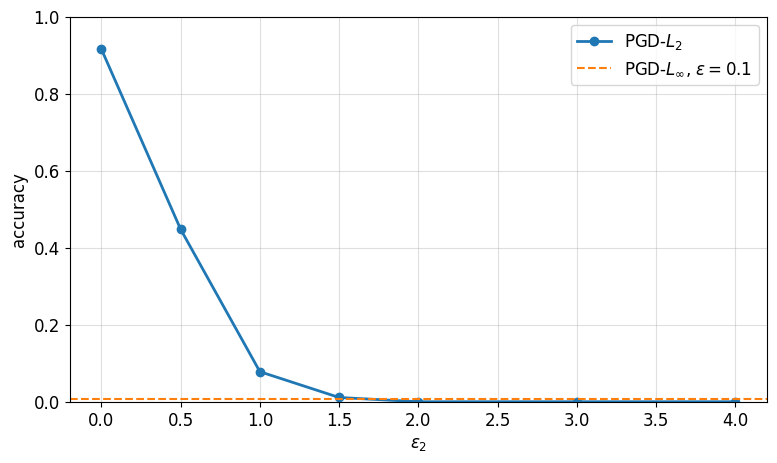

In [51]:
plt.figure(figsize=(9, 5))
plt.plot(eps_l2, acc_l2, 'o-', linewidth=2, label=r'PGD-$L_2$')
plt.axhline(acc_linf, color='tab:orange', linestyle='--', label=r'PGD-$L_\infty$, $\varepsilon = 0.1$')
plt.xlabel(r'$\varepsilon_2$')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

Возмущения обеих атак на одних картинках; $\varepsilon_2$ — ближайшая по accuracy точка проверенной сетки. Если разница велика, сравнение не следует называть сравнением при равной силе атаки. Цветовая шкала каждой карты нормирована отдельно; абсолютные нормы выведены под рисунком:

Ближайшая точка сетки: eps2=1.5, accuracy gap=0.005


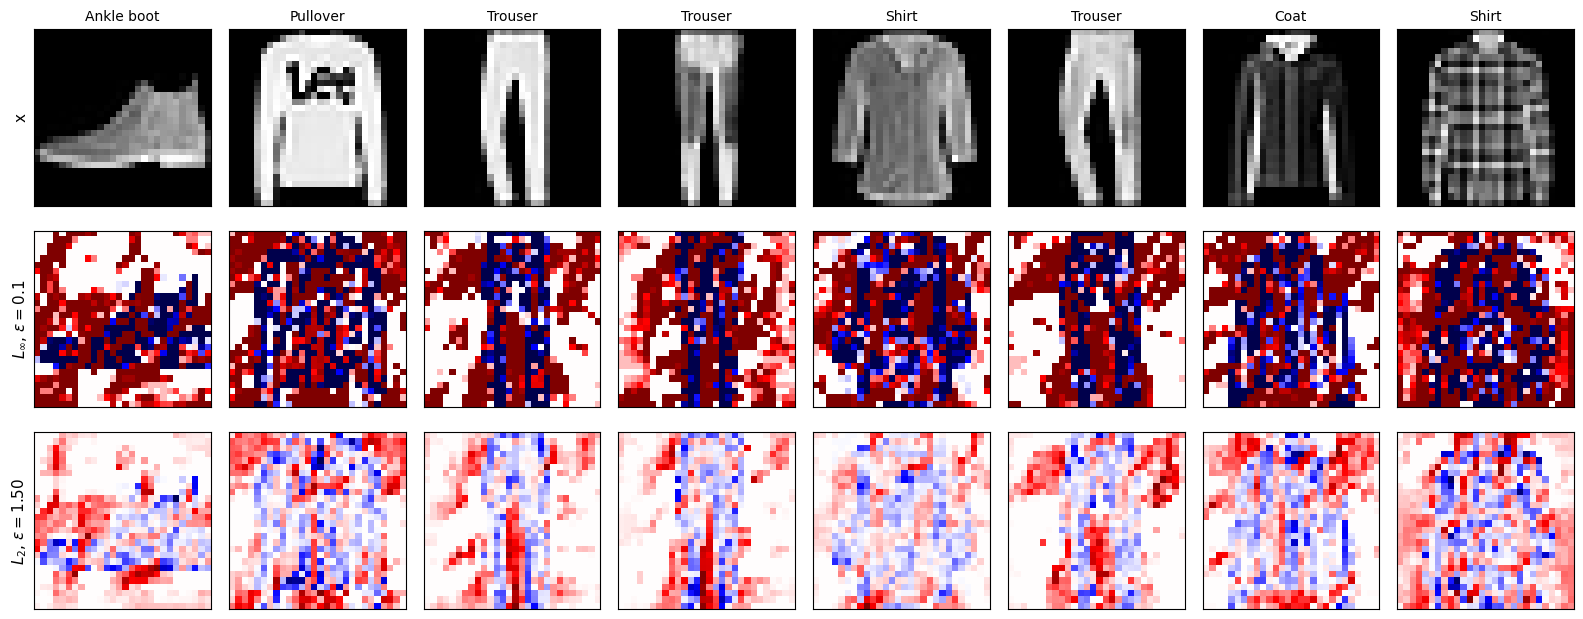

$L_\infty$, $\varepsilon=0.1$ L_inf = 0.100   L_2 = 2.105
$L_2$, $\varepsilon=1.50$    L_inf = 0.247   L_2 = 1.492


In [52]:
# Поиск ближайшей проверенной точки не предполагает монотонность конечной PGD.
match_idx = int(np.argmin(np.abs(np.asarray(acc_l2) - acc_linf)))
eps2_match = float(eps_l2[match_idx])
print(f'Ближайшая точка сетки: eps2={eps2_match}, accuracy gap={abs(acc_l2[match_idx] - acc_linf):.3f}')
x8, y8 = XF_test[:8], YF_test[:8]
torch.manual_seed(0)
deltas = {r'$L_\infty$, $\varepsilon=0.1$': pgd(model_a, x8, y8, 0.1) - x8,
          rf'$L_2$, $\varepsilon={eps2_match:.2f}$': pgd_l2_20(model_a, x8, y8, eps2_match) - x8}
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for i in range(8):
    axes[0, i].imshow(x8[i, 0].cpu(), cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(FM_CLASSES[y8[i]], fontsize=10)
    for row, d in enumerate(deltas.values(), start=1):
        vmax = d[i].abs().max().item()
        axes[row, i].imshow(d[i, 0].cpu(), cmap='seismic', vmin=-vmax, vmax=vmax)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
for ax, label in zip(axes[:, 0], ['x'] + list(deltas)):
    ax.set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()
for name, d in deltas.items():
    print(f'{name:<28} L_inf = {d.abs().amax(dim=(1, 2, 3)).mean():.3f}   L_2 = {d.flatten(1).norm(dim=1).mean():.3f}')

**Вопрос.** Какая точка сетки $\varepsilon_2$ ближе всего по accuracy к $L_\infty$-атаке с $\varepsilon = 0.1$ и как велик остаточный разрыв? Какова $L_2$-норма самого $L_\infty$-возмущения? Где сосредоточено $L_2$-возмущение на ваших изображениях и как это связано с нормированным градиентом?

**Ответ.** Clean accuracy стандартной модели 0.916; PGD-20 $L_\infty$, $\varepsilon = 0.1$ — 0.006 (FGSM — 0.073). PGD-$L_2$ по сетке: 0.448 ($\varepsilon_2 = 0.5$), 0.078 (1.0), **0.011 (1.5)**, 0 (2.0 и выше). Ближайшая точка — $\varepsilon_2 = 1.5$, остаточный разрыв по accuracy 0.005 (5 объектов из 1000), то есть атаки сопоставимой силы (с оговоркой: обе почти насыщены, около нуля разрешение сравнения плохое).

$L_2$-норма самого $L_\infty$-возмущения в среднем по 8 картинкам **2.10** — больше, чем 1.5 у $L_2$-атаки той же силы (и меньше теоретического максимума $0.1 \cdot \sqrt{784} = 2.8$: на фоне $x = 0$ `clamp(0, 1)` пускает возмущение только вверх, часть пикселей обрезается). Зато $L_\infty$-норма $L_2$-возмущения 0.25 — в 2.5 раза больше $\varepsilon_\infty$.

По картинкам: $L_\infty$-возмущение «насыщено» — почти каждый пиксель равен $\pm\varepsilon$, включая фон (там только $+\varepsilon$, красный). $L_2$-возмущение разреженное и неравномерное: оно сосредоточено на силуэте предмета и его контурах (между штанинами брюк, края и складки одежды, воротник), плюс заметные пятна на фоне рядом с предметом, а значительная часть фона почти нулевая. Причина — разный шаг: $L_\infty$-атака использует $\mathrm{sign}(g)$, т.е. тратит одинаковый бюджет на каждый пиксель независимо от $|g_i|$, а $L_2$-шаг $g/\|g\|_2$ распределяет бюджет пропорционально $|g_i|$, концентрируя его в немногих пикселях с наибольшим градиентом. Поэтому при равной силе $L_2$-атака тратит меньшую $L_2$-норму, а $L_\infty$-атака — меньшую $L_\infty$-норму.

## 5.2 Targeted attack (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'targeted'`. Ветку 5.3 при этом можно оставить пустой.

Цель — не просто ошибка, а заданный класс $t$: минимизируем loss по целевой метке
$$
x^{(k+1)} = \Pi_{B_\infty(x, \varepsilon)}\Big[x^{(k)} - \alpha\, \mathrm{sign}\, \nabla_x L\big(f(x^{(k)}), t\big)\Big].
$$

1. Реализуйте `pgd_targeted` ($L_\infty$, random start, как `pgd_attack`).
2. Реализуйте `targeted_success_matrix`: $S[s, t]$ — доля всех картинок класса $s$, которые после атаки с целью $t$ классифицируются как $t$, включая изначально ошибочные. Верните CPU-тензор; диагональ и строки отсутствующих классов — `nan`. Обрабатывайте вход батчами не более 128 объектов, сигнатуру менять не нужно. Сопоставьте результат с готовой clean confusion matrix ниже.

**Оценивание:** код — 1; эксперимент — 0.4; объяснение — 0.6 балла.

In [53]:
if ATTACK_TRACK == 'targeted':
    def pgd_targeted(model, x, target, eps, alpha, steps):
        x = x.detach()
        x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1)   # random start
        for _ in range(steps):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), target), x_adv)
            x_adv = x_adv.detach() - alpha * grad.sign()      # минимизируем loss по целевой метке
            x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
        return x_adv.detach()


    def targeted_success_matrix(model, x, y, eps, steps=20, n_classes=10):
        model.eval()
        alpha = 2.5 * eps / steps
        y_cpu = y.cpu()
        counts = torch.bincount(y_cpu, minlength=n_classes).float()
        hits = torch.zeros(n_classes, n_classes)
        for t in range(n_classes):
            preds = []
            for i in range(0, len(x), 128):                      # батчи не более 128 объектов
                xb = x[i:i + 128]
                target = torch.full((len(xb),), t, dtype=y.dtype, device=y.device)
                x_adv = pgd_targeted(model, xb, target, eps, alpha, steps)
                with torch.no_grad():
                    preds.append(model(x_adv).argmax(dim=1))
            hit = (torch.cat(preds) == t).float().cpu()         # включая изначально ошибочные
            hits[:, t] = torch.bincount(y_cpu, weights=hit, minlength=n_classes)
        S = hits / counts.clamp_min(1)[:, None]
        S[counts == 0] = float('nan')
        S.fill_diagonal_(float('nan'))
        return S


In [54]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    x, y = XF_test[:1000], YF_test[:1000]
    target = (y + 1) % 10
    x_t = pgd_targeted(model_a, x, target, eps=0.1, alpha=0.0125, steps=20)
    assert (x_t - x).abs().max() <= 0.1 + 1e-6 and x_t.min() >= 0 and x_t.max() <= 1
    assert_no_param_grads(model_a)
    with torch.no_grad():
        hit_rate = (model_a(x_t).argmax(dim=1) == target).float().mean().item()
    print(f'Targeted hit rate: {hit_rate:.3f}; сравните с частотой целевого класса до атаки.')
    hit_rate

Targeted hit rate: 0.760; сравните с частотой целевого класса до атаки.


Clean confusion matrix (строки: true, столбцы: predicted):
[[0.93 0.   0.01 0.03 0.   0.   0.04 0.   0.   0.  ]
 [0.   0.99 0.   0.01 0.   0.   0.   0.   0.   0.  ]
 [0.03 0.   0.85 0.01 0.06 0.   0.05 0.   0.   0.  ]
 [0.05 0.   0.01 0.88 0.03 0.   0.02 0.   0.   0.  ]
 [0.   0.   0.06 0.03 0.89 0.   0.03 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.98 0.   0.01 0.   0.01]
 [0.09 0.   0.06 0.03 0.07 0.   0.74 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.99 0.01 0.  ]
 [0.   0.   0.   0.   0.   0.   0.01 0.   0.99 0.  ]
 [0.   0.   0.   0.   0.   0.01 0.   0.04 0.   0.95]]


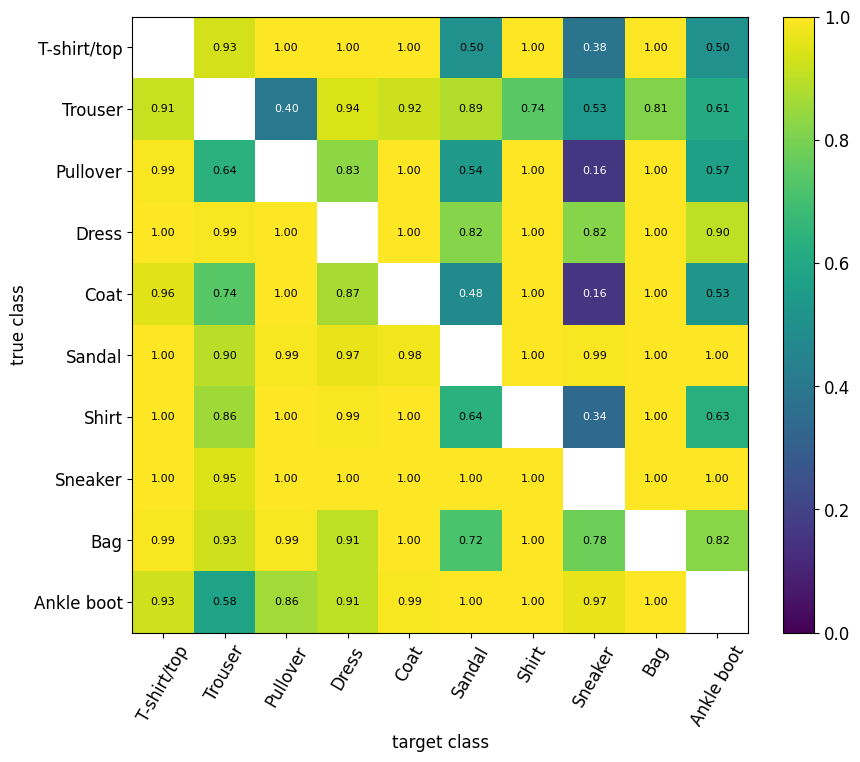

In [55]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    S = targeted_success_matrix(model_a, XF_test, YF_test, eps=0.1)
    assert S.shape == (10, 10) and torch.isnan(S.diagonal()).all()
    pred_clean = predict_logits(model_a, XF_test).argmax(1)
    clean_confusion = torch.bincount((10 * YF_test + pred_clean).cpu(), minlength=100).reshape(10, 10).float()
    clean_confusion /= clean_confusion.sum(1, keepdim=True).clamp_min(1)
    print('Clean confusion matrix (строки: true, столбцы: predicted):')
    print(np.round(clean_confusion.numpy(), 2))

    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(S, cmap='viridis', vmin=0, vmax=1)
    for s, t in itertools.product(range(10), range(10)):
        if s != t:
            ax.text(t, s, f'{S[s, t]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if S[s, t] < 0.5 else 'black')
    ax.set_xticks(range(10), FM_CLASSES, rotation=60)
    ax.set_yticks(range(10), FM_CLASSES)
    ax.set_xlabel('target class')
    ax.set_ylabel('true class')
    plt.colorbar(im, fraction=0.046)
    plt.show()

**Вопрос.** Какие пары (истинный класс, целевой класс) атакуются легче всего, какие труднее? Симметрична ли матрица? Как это связано с тем, какие классы модель путает без атаки?

**Ответ.** Targeted PGD-20 с $\varepsilon = 0.1$ очень силён: для цели $t = (y + 1) \bmod 10$ hit rate 0.760, тогда как без атаки модель предсказывает «соседний» класс лишь в долях процента (недиагональные элементы clean confusion — в основном 0.00–0.09). В матрице $S$ большинство пар $\ge 0.9$.

- **Легче всего:** пары внутри «верхней одежды» (T-shirt, Pullover, Dress, Coat, Shirt) — в основном 1.00 (минимум Pullover → Dress 0.83); любые цели для Sandal и Sneaker (0.90–1.00); Ankle boot → Sandal/Shirt/Bag = 1.00; Trouser → Dress 0.94.
- **Труднее всего:** превратить верхнюю одежду в Sneaker (Pullover → Sneaker 0.16, Coat → Sneaker 0.16, Shirt → Sneaker 0.34, T-shirt → Sneaker 0.38) или в Sandal / Ankle boot (0.48–0.64); Trouser → Pullover 0.40; Ankle boot → Trouser 0.58; Pullover → Trouser 0.64.

Матрица заметно **несимметрична**: Sneaker → Pullover/Coat = 1.00, а Pullover/Coat → Sneaker = 0.16; Trouser → Pullover 0.40 при Pullover → Trouser 0.64; Bag → Sandal 0.72 при Sandal → Bag 1.00. Атака легче, когда целевой класс «рядом» в пространстве признаков или имеет широкую область решений: у обуви мало ярких пикселей, и её картинку легко «дорисовать» до чего угодно, а большой яркий силуэт свитера трудно превратить в маленький кроссовок за $\pm 0.1$ на пиксель.

Связь с clean confusion: пары, которые модель путает без атаки, атакуются легко — Shirt ↔ T-shirt/Pullover/Coat (без атаки Shirt → T-shirt 0.09, Shirt → Coat 0.07; под атакой 1.00), Pullover ↔ Coat (0.06; под атакой 1.00), Coat → Pullover. Но обратное неверно: высокий успех бывает и для пар без clean-путаницы (Sandal → Dress 0.97, Trouser → Coat 0.92) — при $\varepsilon = 0.1$ почти любая цель достижима, и clean confusion объясняет скорее, какие пары **трудные** (далёкие классы с разной геометрией: верх ↔ обувь, брюки ↔ свитер), чем какие лёгкие. Ограничение: по ~100 объектов в классе (1000 test), т.е. погрешность отдельной ячейки ~±5 п.п.

## 5.3 Transfer (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'transfer'`. Ветку 5.2 при этом можно оставить пустой.

Black-box сценарий: атакующий не видит модель-жертву, строит атаку на своей модели и надеется, что она перенесётся. Обучите `model_b` (та же архитектура, `set_seed(1)`) и MLP с двумя скрытыми слоями по 512 нейронов и ReLU (`set_seed(2)`). Атаки FGSM и PGD-20 с $\varepsilon = 0.1$, построенные на `model_a`, проверьте на всех трёх моделях. Результат — `transfer[attack][victim] = accuracy`, атаки `'clean'`, `'FGSM'`, `'PGD-20'`, жертвы `'model A (source)'`, `'model B'`, `'MLP'`.

**Оценивание:** код — 0.6; эксперимент — 0.8; объяснение — 0.6 балла.

In [56]:
if ATTACK_TRACK == 'transfer':
    # ваш код
    raise NotImplementedError
    print(f'{"":<8}' + ''.join(f'{name:>18}' for name in transfer['clean']))
    for attack, row in transfer.items():
        print(f'{attack:<8}' + ''.join(f'{acc:>18.3f}' for acc in row.values()))

**Вопрос.** Для каждой жертвы укажите падение accuracy относительно её собственного clean baseline. Сравните с падением на source-модели. Какая атака и на какую архитектуру переносится лучше в вашем прогоне? Предложите объяснение и укажите, почему одного seed недостаточно для общего вывода о превосходстве архитектуры или атаки.

**Ответ.** 

---
# 6. Adversarial training

## 6.1 PGD adversarial training (2 балла)

[Towards Deep Learning Models Resistant to Adversarial Attacks](https://arxiv.org/pdf/1706.06083), Madry et al., 2017:
$$
\min_\theta\; \mathbb E_{(x, y)} \Big[\max_{\|\delta\|_\infty \le \varepsilon} L\big(f_\theta(x + \delta), y\big)\Big].
$$
На каждом батче внутренний max приближается атакой, и шаг оптимизатора делается только по adversarial-примерам, без clean-части. Модель — с нуля.

Реализуйте `adversarial_train(model, eps, attack, epochs)`: `attack(model, x, y, eps)` возвращает detached `x_adv`. Используйте `torch.optim.Adam` с переданным `lr`, batch size 128, cross-entropy только на adversarial-примерах. Генерация атаки — в `eval()`, обновление весов — в `train()`; не дифференцируйте через построение атаки. После каждой эпохи записывайте clean, FGSM и PGD-20 accuracy на `XF_test[:1000]` с тем же $\varepsilon$. Перед возвратом включите `eval()` и очистите `.grad` параметров.

В обязательной части обучается одна модель с PGD-7. FGSM и FGSM-RS из готового словаря нужны только для бонуса 7.5.

**Оценивание:** код — 1; эксперимент — 0.6; объяснение — 0.4 балла.

In [57]:
def fgsm_rs_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=1.25 * eps, steps=1, random_start=True)


def pgd7_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / 7, steps=7)


TRAIN_ATTACKS = {'FGSM': fgsm_attack, 'FGSM-RS': fgsm_rs_attack, 'PGD-7': pgd7_attack}
AT_EPOCHS = 2 if FAST_MODE else 5

In [58]:
def adversarial_train(model, eps, attack, epochs=AT_EPOCHS, lr=1e-3, log=True):
    model = model.to(device)
    history = dict(clean=[], fgsm=[], pgd=[])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    x_eval, y_eval = XF_test[:1000], YF_test[:1000]
    start = time.time()
    for epoch in range(epochs):
        for xb, yb in iterate_batches(XF_train, YF_train, 128):
            model.eval()
            x_adv = attack(model, xb, yb, eps).detach()          # внутренний max — атакой, без градиента через неё
            model.train()
            loss = F.cross_entropy(model(x_adv), yb)             # только adversarial-примеры
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
        model.eval()
        history['clean'].append(attack_accuracy(model, x_eval, y_eval))
        history['fgsm'].append(attack_accuracy(model, x_eval, y_eval, fgsm_attack, eps=eps))
        history['pgd'].append(attack_accuracy(model, x_eval, y_eval, pgd, eps=eps))
        if log:
            print(f'epoch {epoch + 1}/{epochs}  clean {history["clean"][-1]:.3f}  '
                  f'FGSM {history["fgsm"][-1]:.3f}  PGD-20 {history["pgd"][-1]:.3f}  {time.time() - start:.0f}s')
    model.eval()
    model.zero_grad(set_to_none=True)
    return history


In [59]:
EPS_TRAIN = 0.1
robust, at_history = {}, {}
for name in ['PGD-7']:
    print(name)
    set_seed(0)
    robust[name] = SmallCNN()
    started = time.perf_counter()
    at_history[name] = adversarial_train(robust[name], EPS_TRAIN, TRAIN_ATTACKS[name])
    RUN_TIMES['fashion_pgd_at_seconds'] = time.perf_counter() - started
if not FAST_MODE and at_history['PGD-7']['pgd'][-1] <= 0.5:
    print('PGD accuracy ниже ориентира 0.5: проверьте обучение и обсудите результат; это не автопровал задания.')

PGD-7
epoch 1/5  clean 0.808  FGSM 0.702  PGD-20 0.664  10s
epoch 2/5  clean 0.824  FGSM 0.702  PGD-20 0.660  19s
epoch 3/5  clean 0.823  FGSM 0.724  PGD-20 0.701  29s
epoch 4/5  clean 0.835  FGSM 0.719  PGD-20 0.694  38s
epoch 5/5  clean 0.842  FGSM 0.751  PGD-20 0.717  48s


In [60]:
eps_grid = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3]
models_eval = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
torch.manual_seed(0)
robust_curves = {name: [attack_accuracy(m, XF_test, YF_test, pgd, eps=e) if e > 0 else attack_accuracy(m, XF_test, YF_test)
                        for e in eps_grid] for name, m in models_eval.items()}
for name, accs in robust_curves.items():
    print(f'{name:<10}' + ''.join(f'{a:>8.3f}' for a in accs))

standard     0.916   0.119   0.005   0.000   0.000   0.000
PGD-AT       0.842   0.790   0.719   0.476   0.137   0.001


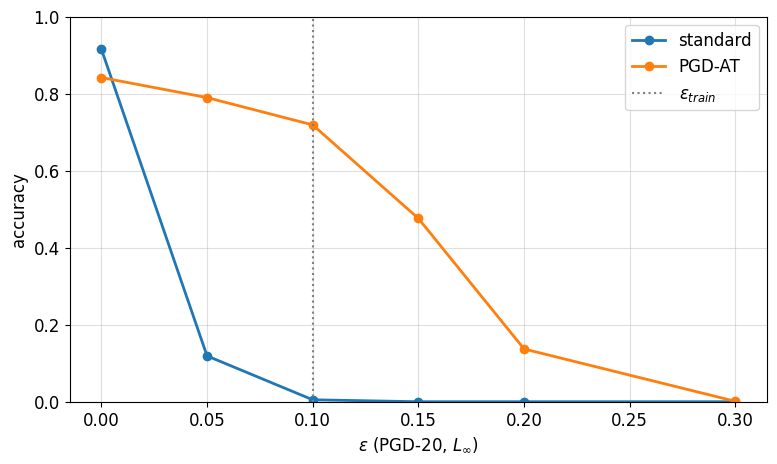

In [61]:
plt.figure(figsize=(9, 5))
for name, accs in robust_curves.items():
    plt.plot(eps_grid, accs, 'o-', linewidth=2, label=name)
plt.axvline(EPS_TRAIN, color='gray', linestyle=':', label=r'$\varepsilon_{train}$')
plt.xlabel(r'$\varepsilon$ (PGD-20, $L_\infty$)')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Сколько стоит робастность в clean accuracy? Что происходит при $\varepsilon > \varepsilon_{\text{train}}$? Во сколько раз PGD-AT дороже обычного обучения по числу forward/backward?

**Ответ.** Clean accuracy: стандартная модель 0.916, PGD-AT 0.842 — робастность стоит **≈7.4 п.п.** clean accuracy. Взамен PGD-20 accuracy при $\varepsilon = 0.1$ выросла с 0.005 до **0.719** (по эпохам AT: 0.664 → 0.717, clean 0.808 → 0.842).

PGD-20 accuracy по $\varepsilon$ (0, 0.05, 0.1, 0.15, 0.2, 0.3): standard — 0.916, 0.119, 0.005, 0, 0, 0; PGD-AT — 0.842, 0.790, 0.719, 0.476, 0.137, 0.001. При $\varepsilon > \varepsilon_{\text{train}} = 0.1$ робастность быстро исчезает: 0.48 при 0.15, 0.14 при 0.2 и ноль при 0.3. Модель защищена только в том шаре, на котором её обучали: за пределами $\varepsilon_{\text{train}}$ гарантий нет, а при $\varepsilon = 0.3$ (почти треть диапазона пикселя) атака может реально «перерисовать» объект. Тем не менее при любом $\varepsilon \le 0.2$ PGD-AT многократно лучше стандартной модели.

Стоимость: на каждом батче PGD-7 делает 7 forward + 7 backward по входу, плюс 1 forward/backward для шага по весам — **≈8×** вычислений обычного обучения (без учёта ежеэпохальной оценки clean/FGSM/PGD-20). По времени: стандартная модель обучилась за 7.9 с, PGD-AT — за 47.8 с (6.1×); время PGD-AT включает и оценку после каждой эпохи, а на маленькой CNN на GPU заметен overhead запуска ядер, поэтому отношение по времени не обязано совпадать с 8×.

## 6.2 Диагностика оценки robustness (1 балл)

Реализуйте `sanity_checks(model, x, y, eps)` и верните четыре accuracy:

- `fgsm` — после FGSM;
- `pgd20` — после PGD-20 с random start;
- `pgd100_x5` — PGD-100 с пятью random restarts: объект считается сломанным, если он ошибочно классифицирован хотя бы в одном restart **или уже на clean**;
- `eps_1` — после PGD-20 с $\varepsilon=1$.

Для каждого поля clean-ошибки тоже считаются ошибками: атака не должна «исправлять» robust accuracy. Атакуйте батчами не более 128. В `FAST_MODE` сокращается только число объектов, число шагов и restarts остаётся тем же.

Обычно усиление атаки уменьшает accuracy; обратный результат — повод проверить step size, random start и loss. Независимые конечные PGD-прогоны не дают гарантированного порядка результатов. Низкая accuracy при большом радиусе — полезная диагностика, но прохождение всех sanity checks не доказывает отсутствие gradient masking и не сертифицирует robustness. См. [Athalye et al., 2018](https://arxiv.org/abs/1802.00420).

Эксперимент проводится на фиксированных первых 128 объектах в FAST_MODE и 256 в финальном режиме. Это диагностика, а не точная оценка accuracy всего датасета.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [62]:
def sanity_checks(model, x, y, eps):
    model.eval()
    correct = dict(fgsm=0, pgd20=0, pgd100_x5=0, eps_1=0)
    for i in range(0, len(x), 128):                             # батчи не более 128
        xb, yb = x[i:i + 128], y[i:i + 128]

        def is_correct(x_in):
            with torch.no_grad():
                return model(x_in).argmax(dim=1) == yb

        ok_clean = is_correct(xb)                               # clean-ошибки остаются ошибками
        correct['fgsm'] += (ok_clean & is_correct(fgsm_attack(model, xb, yb, eps))).sum().item()
        correct['pgd20'] += (ok_clean & is_correct(pgd(model, xb, yb, eps, steps=20))).sum().item()
        robust = ok_clean.clone()
        for _ in range(5):                                      # 5 random restarts PGD-100: сломан хотя бы раз
            robust &= is_correct(pgd(model, xb, yb, eps, steps=100))
        correct['pgd100_x5'] += robust.sum().item()
        correct['eps_1'] += (ok_clean & is_correct(pgd(model, xb, yb, 1.0, steps=20))).sum().item()
    return {k: v / len(x) for k, v in correct.items()}


In [63]:
torch.manual_seed(0)
N_SANITY = 128 if FAST_MODE else 256
checks = {name: sanity_checks(m, XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_TRAIN)
          for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
print(f'{"model":<22}' + ''.join(f'{k:>11}' for k in next(iter(checks.values()))))
for name, res in checks.items():
    assert set(res) == {'fgsm', 'pgd20', 'pgd100_x5', 'eps_1'}
    assert all(math.isfinite(v) and 0 <= v <= 1 for v in res.values())
    print(f'{name:<22}' + ''.join(f'{v:>11.3f}' for v in res.values()))

model                        fgsm      pgd20  pgd100_x5      eps_1
standard                    0.082      0.012      0.008      0.000
PGD-AT                      0.758      0.730      0.723      0.000


**Вопрос.** Насколько меняется оценка accuracy при усилении атаки? Есть ли подозрительные результаты и что вы проверили бы дополнительно? Может ли модель с высокой FGSM accuracy и почти нулевой PGD accuracy пройти все перечисленные sanity checks — и что тогда можно сказать о её robustness?

**Ответ.** На первых 256 test-объектах ($\varepsilon = 0.1$):

| модель | FGSM | PGD-20 | PGD-100 × 5 | PGD-20, $\varepsilon = 1$ |
|---|---|---|---|---|
| standard | 0.082 | 0.012 | 0.008 | 0.000 |
| PGD-AT | 0.758 | 0.730 | 0.723 | 0.000 |

Оценка монотонно падает при усилении атаки, как и должно быть. Для PGD-AT переход FGSM → PGD-20 снимает 2.8 п.п., а PGD-20 → PGD-100 с пятью restarts — всего 0.8 п.п. (два объекта из 256): PGD-20 уже почти сошёлся, и усиление атаки не обнаруживает «скрытых» уязвимостей. При $\varepsilon = 1$ (весь диапазон пикселя) обе модели падают в ноль — атака умеет ломать модель, если ей разрешено. Подозрительных результатов я не вижу. Дополнительно я бы проверил: атаки без градиента (Square Attack) и transfer-атаку с другой модели, AutoAttack (APGD-CE/DLR с адаптивным шагом), кривую accuracy от числа шагов и от $\varepsilon$ на мелкой сетке, другую loss (CW/margin) — и всё это на большей выборке, т.к. 256 объектов дают погрешность ≈±3 п.п.

Модель с высокой FGSM и почти нулевой PGD accuracy **может пройти** все перечисленные проверки: «PGD ≤ FGSM», «PGD-100×5 ≤ PGD-20», «$\varepsilon = 1$ → 0» выполнены. Именно такая модель получилась в бонусе 7.5 (FGSM-AT при $\varepsilon = 0.2$: FGSM 0.62, PGD-20 0, PGD-100×5 0, $\varepsilon = 1$ → 0). О ней можно сказать, что она **не робастна**: робастная accuracy — это минимум по атакам, т.е. ≈0, а высокая FGSM accuracy — артефакт gradient masking (линейное приближение в одном шаге указывает в бесполезную сторону). Прохождение sanity checks — необходимое, но не достаточное условие; оно не сертифицирует робастность.

## 6.3 Градиент по входу у обычной и робастной модели (1 балл)

Карта $|\nabla_x z_y(x)|$ — saliency по логиту верного класса: $z_c(x)$ обозначает логит класса $c$, $y$ — верную метку. Это **другая величина**, чем градиент cross-entropy в FGSM. Если $p_c(x)=\mathrm{softmax}(z(x))_c$, то
$$
\nabla_x L_{\mathrm{CE}}(x,y)=\sum_c p_c(x)\nabla_x z_c(x)-\nabla_x z_y(x).
$$
Для некоторых adversarially trained моделей наблюдали более интерпретируемые input gradients ([Tsipras et al., 2019](https://arxiv.org/pdf/1805.12152)). Здесь проверяется, наблюдается ли такой эффект в нашем протоколе; вид saliency сам по себе не доказывает robustness.

1. Реализуйте `input_gradient(model, x, y)`, возвращающую $|\nabla_x z_y|$ для батча (без изменения `.grad` параметров).
2. Для стандартной модели и PGD-AT посчитайте долю массы градиента на фоне (пиксели с $x = 0$), среднюю по `XF_test[:1000]`, и нарисуйте карты для 8 картинок.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [64]:
def input_gradient(model, x, y):
    model.eval()
    x = x.detach()
    if x.device.type == 'cpu':
        x_in = x.clone().requires_grad_(True)
        with torch.enable_grad():
            z_y = model(x_in).gather(1, y.view(-1, 1)).sum()   # логиты верного класса, сумма по батчу
            grad, = torch.autograd.grad(z_y, x_in)             # градиент по входу; .grad параметров не трогаем
        return grad.abs()
    # На GPU в MaxPool бывают равные значения в окне (фон x = 0 после свёртки с bias > 0 и ReLU),
    # и выбор argmax среди них в CUDA-ядре зависит от размера батча: градиент «прыгает» между
    # равными пикселями. Чтобы результат не зависел от батча, считаем по одному объекту;
    # deterministic-режим cuDNN убирает расхождения ~1e-7 между повторными вызовами.
    torch.backends.cudnn.deterministic = True
    grads = []
    for i in range(len(x)):
        xi = x[i:i + 1].clone().requires_grad_(True)
        with torch.enable_grad():
            gi, = torch.autograd.grad(model(xi)[0, y[i]], xi)
        grads.append(gi)
    return torch.cat(grads).abs()


def background_share(s, x):
    return ((s * (x == 0)).flatten(1).sum(1) / s.flatten(1).sum(1).clamp_min(1e-12)).mean().item()


In [65]:
x, y = XF_test[:1000], YF_test[:1000]
g = input_gradient(model_a, x, y)
assert g.shape == x.shape and (g >= 0).all()
assert_no_param_grads(model_a)
x1 = x[:1].clone().requires_grad_(True)
manual, = torch.autograd.grad(model_a(x1)[0, y[0]], x1)
assert torch.allclose(g[:1], manual.abs())

grad_models = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
shares = {name: background_share(input_gradient(m, x, y), x) for name, m in grad_models.items()}
print(f'background pixels: {(x == 0).float().mean():.3f}')
shares

background pixels: 0.498


{'standard': 0.5944791436195374, 'PGD-AT': 0.22374434769153595}

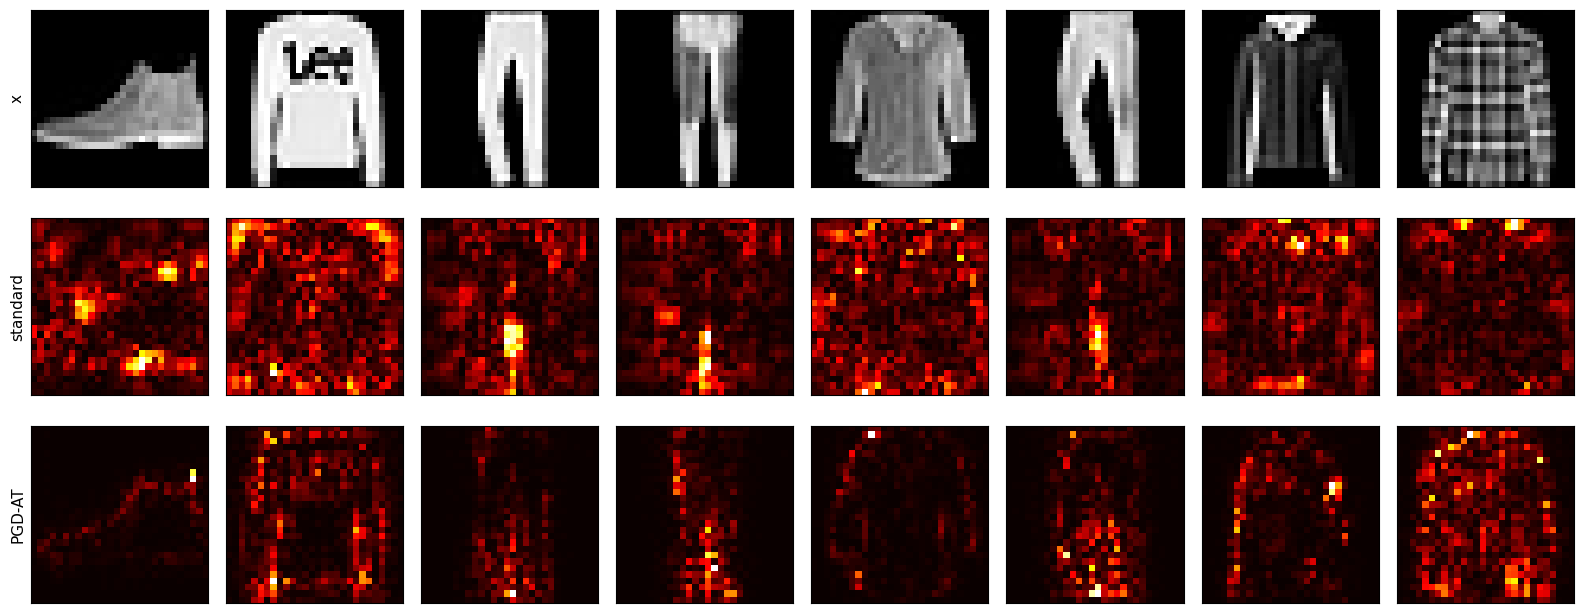

In [66]:
x8, y8 = XF_test[:8], YF_test[:8]
rows = {'x': x8} | {name: input_gradient(m, x8, y8) for name, m in grad_models.items()}
fig, axes = plt.subplots(len(rows), 8, figsize=(16, 2.2 * len(rows)))
for row, (label, images) in enumerate(rows.items()):
    for i in range(8):
        axes[row, i].imshow(images[i, 0].cpu(), cmap='gray' if row == 0 else 'hot')
        axes[row, i].set_xticks([])
        axes[row, i].set_yticks([])
    axes[row, 0].set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()

**Вопрос.** Чем отличаются карты моделей — визуально и по доле массы на фоне? Согласуется ли наблюдение с различием PGD accuracy в вашем эксперименте? Почему одной красивой saliency-карты недостаточно для вывода о robustness?

**Ответ.** Доля массы $|\nabla_x z_y|$ на фоне (пиксели $x = 0$ занимают 49.8% изображения) на `XF_test[:1000]`: **0.594** у стандартной модели и **0.224** у PGD-AT. У стандартной модели градиент даже чуть «предпочитает» фон (0.594 > 0.498), а у робастной массы на фоне почти втрое меньше — она сосредоточена на объекте.

Визуально: карты стандартной модели шумные, «зернистые», с яркими пятнами по всему кадру, включая пустой фон (у ботинка и брюк самые яркие точки вне объекта или в зазоре между штанинами); форма предмета по ним угадывается плохо. Карты PGD-AT заметно чище: фон тёмный, энергия собрана на силуэте и контурах (края куртки, клетка рубашки, контур ботинка), т.е. карта похожа на сам предмет — как в Tsipras et al.

Это согласуется с разницей в робастности (PGD-20 accuracy 0.719 vs 0.005): стандартная модель чувствительна к пикселям фона, которые человек считает несущественными, и именно туда $L_\infty$-атака легко добавляет $+\varepsilon$. Но одной красивой карты недостаточно для вывода о robustness: saliency — локальная информация первого порядка в одной точке, а робастность — свойство худшего случая во всём шаре $\|\delta\|_\infty \le \varepsilon$; модель с замаскированными градиентами может иметь «аккуратный» градиент и всё равно ломаться атакой. Кроме того, визуальная оценка субъективна, посмотрено 8 картинок, а $|\nabla z_y|$ — не тот градиент, который использует атака (градиент CE). Вывод о робастности даёт только сильная атака (6.1–6.2), saliency лишь согласуется с ним.

*Техническое замечание:* на GPU открытый тест `allclose(g[:1], manual)` сначала падал: в MaxPool на фоне бывают равные значения в окне (после свёртки с положительным bias и ReLU), и CUDA-ядро выбирает argmax среди них по-разному в зависимости от размера батча. Поэтому `input_gradient` на GPU считает градиент по одному объекту в deterministic-режиме cuDNN; на CPU используется батчевый вариант.

### Сохранение результатов обязательной части

Ячейка сохраняет `metrics.json` и три checkpoint в `artifacts/`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode=false`. Сдайте их вместе с ноутбуком. NaN в матрице targeted success записываются как JSON `null`. Checkpoints содержат только `state_dict`, без сериализации объекта модели.

In [67]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    schema_version=2, fast_mode=FAST_MODE, attack_track=ATTACK_TRACK,
    environment=dict(torch=torch.__version__, device=str(device)),
    data=dict(cifar_train=len(X_train), cifar_test=len(X_test),
              fashion_train=len(XF_train), fashion_test=len(XF_test)),
    config=dict(seed=0, cifar_epochs=EPOCHS, ablation_epochs=ABL_EPOCHS,
                cifar_lr=LR, cifar_mean=CIFAR_MEAN, cifar_std=CIFAR_STD,
                fashion_epochs=FM_EPOCHS, at_epochs=AT_EPOCHS, eps_train=EPS_TRAIN),
    cifar=dict(history=history_cifar, ablations=ablation),
    attacks=dict(l2_eps=eps_l2, l2_accuracy=acc_l2, linf_accuracy=acc_linf,
                 selected=S if ATTACK_TRACK == 'targeted' else transfer),
    adversarial=dict(history=at_history, eps=eps_grid, accuracy=robust_curves,
                     sanity=checks, background_share=shares),
    timings=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2,
                                                    allow_nan=False), encoding='utf-8')
for name, model in [('resnet20', resnet20), ('fashion_standard', model_a), ('fashion_pgd_at', robust['PGD-7'])]:
    torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, artifact_dir / f'{name}.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['fashion_pgd_at.pt', 'fashion_standard.pt', 'metrics.json', 'resnet20.pt']


---
# 7\*. Бонусные задачи

## 7.1 Edge of stability (1.5 балла)

Для положительно определённой квадратичной функции GD сходится при $0 < \eta < 2/\lambda_{\max}$, где $\lambda_{\max}$ — наибольшее собственное число гессиана. [Gradient Descent on Neural Networks Typically Occurs at the Edge of Stability](https://arxiv.org/pdf/2103.00065), Cohen et al., 2021: у нейросети sharpness $\lambda_{\max}(\nabla^2 L)$ во время full-batch GD растёт (progressive sharpening), пока не дойдёт до $2/\eta$, и дальше держится около этой границы — loss при этом немонотонный, но продолжает убывать.

1. Реализуйте `hvp(grads, params, v)`: градиент считается один раз с `create_graph=True`, а $Hv$ — VJP градиента с вектором $v$ (`grad_outputs` в `torch.autograd.grad`); гессиан $H$ явно не строится.
2. `top_eigenvalue` ниже — готовый Lanczos с reorthogonalization. Он оценивает **наибольшее algebraic eigenvalue** через наибольшее eigenvalue небольшой tridiagonal matrix. Обычная power iteration для indefinite Hessian может найти отрицательное eigenvalue с наибольшим модулем и здесь не подходит. Менять готовый solver не требуется; проверьте HVP и solver на тестах, включая indefinite quadratic.
3. Full-batch GD (`SGD` без momentum) для MLP с двумя скрытыми слоями по 200 нейронов и tanh на первых 2000 картинках FashionMNIST, loss — MSE по one-hot $\frac12 \|f(x) - e_y\|^2$ (среднее по объектам). Для нескольких $\eta$ записывать loss на каждом шаге и $\lambda_{\max}$ каждые 50 шагов. График: $\lambda_{\max}$ по шагам с горизонталями $2/\eta$.

**Оценивание:** код — 0.7; эксперимент — 0.4; объяснение — 0.4 балла.

In [68]:
if '7.1' in BONUS_TASKS:
    def hvp(grads, params, v):
        # grads = torch.autograd.grad(loss, params, create_graph=True); v — список тензоров формы params
        # Hv = d/dtheta <grad, v> — VJP градиента с вектором v; граф сохраняем для повторных вызовов
        return list(torch.autograd.grad(grads, params, grad_outputs=list(v), retain_graph=True))


    def top_eigenvalue(loss_fn, params, iters=20, v=None):
        # Готовый solver: largest algebraic Ritz value, не eigenvalue наибольшего модуля.
        params = list(params)
        sizes = [p.numel() for p in params]
        total = sum(sizes)
        if iters < 1:
            raise ValueError('iters must be positive')
        def unpack(flat):
            return [part.view_as(p) for part, p in zip(flat.split(sizes), params)]
        q = torch.randn(total, device=params[0].device, dtype=params[0].dtype)
        if v is not None:
            # Небольшой шум не даёт warm start застрять в одном инвариантном подпространстве.
            q = torch.cat([vi.detach().flatten() for vi in v]) + 1e-3 * q / q.norm()
        q = q / q.norm()
        grads = torch.autograd.grad(loss_fn(), params, create_graph=True)
        basis, diagonal, off_diagonal = [], [], []
        for k in range(min(iters, total)):
            basis.append(q)
            z = torch.cat([h.detach().flatten() for h in hvp(grads, params, unpack(q))])
            if k:
                z = z - off_diagonal[-1] * basis[-2]
            alpha = torch.dot(q, z)
            diagonal.append(alpha)
            z = z - alpha * q
            Q = torch.stack(basis)
            for _ in range(2):
                z = z - (Q @ z) @ Q
            beta = z.norm()
            if beta.item() < 1e-7 or k + 1 == min(iters, total):
                break
            off_diagonal.append(beta)
            q = z / beta
        T = torch.diag(torch.stack(diagonal))
        if off_diagonal:
            off = torch.stack(off_diagonal)
            T += torch.diag(off, diagonal=1) + torch.diag(off, diagonal=-1)
        # Маленькая eigenproblem на CPU, в том числе при основном обучении на MPS.
        values, vectors = torch.linalg.eigh(T.cpu().double())
        coeffs = vectors[:, -1].to(device=q.device, dtype=q.dtype)
        eigenvector = coeffs @ torch.stack(basis)
        return values[-1].item(), unpack(eigenvector)

In [69]:
if '7.1' in BONUS_TASKS:
    torch.manual_seed(0)
    Q = torch.linalg.qr(torch.randn(30, 30))[0]
    A = Q @ torch.diag(torch.linspace(0.1, 7, 30)) @ Q.T
    w = torch.randn(30, requires_grad=True)
    grads = torch.autograd.grad(0.5 * w @ A @ w, [w], create_graph=True)
    v = torch.randn(30)
    assert torch.allclose(hvp(grads, [w], [v])[0], A @ v, atol=1e-5)

    p = torch.tensor([1.0, -2.0], requires_grad=True)
    lam, _ = top_eigenvalue(lambda: 0.5 * (p[0] ** 2 + 20 * p[1] ** 2), [p], iters=50)
    assert abs(lam - 20) < 1e-3
    lam, _ = top_eigenvalue(lambda: 0.5 * w @ A @ w, [w], iters=300)
    assert abs(lam - 7) < 1e-2
    lam, _ = top_eigenvalue(lambda: 0.5 * (-10 * p[0] ** 2 + 2 * p[1] ** 2), [p], iters=10)
    assert abs(lam - 2) < 1e-4, lam

In [70]:
if '7.1' in BONUS_TASKS:
    N_EOS = 256 if FAST_MODE else 2000
    EOS_STEPS = 100 if FAST_MODE else 3000
    X_eos = XF_train[:N_EOS].flatten(1)
    X_eos = X_eos - X_eos.mean(dim=0)
    Y_eos = F.one_hot(YF_train[:N_EOS], 10).float()


    def make_tanh_mlp(seed=0):
        torch.manual_seed(seed)
        return nn.Sequential(nn.Linear(784, 200), nn.Tanh(), nn.Linear(200, 200), nn.Tanh(), nn.Linear(200, 10)).to(device)


    def mse_loss(model):
        return 0.5 * ((model(X_eos) - Y_eos) ** 2).sum(dim=1).mean()

eta=0.02: 2/eta = 100.0; sharpness start 4.44, max 17.15, final 17.15; loss 0.4973 -> 0.1494; 7s
eta=0.05: 2/eta = 40.0; sharpness start 4.44, max 42.43, final 38.17; loss 0.4973 -> 0.1101; 7s
eta=0.1: 2/eta = 20.0; sharpness start 4.44, max 22.39, final 21.04; loss 0.4973 -> 0.0859; 7s
eta=0.2: 2/eta = 10.0; sharpness start 4.44, max 12.34, final 10.99; loss 0.4973 -> 0.0691; 7s
eta=0.4: 2/eta = 5.0; sharpness start 4.44, max 7.01, final 5.60; loss 0.4973 -> 0.0412; 7s


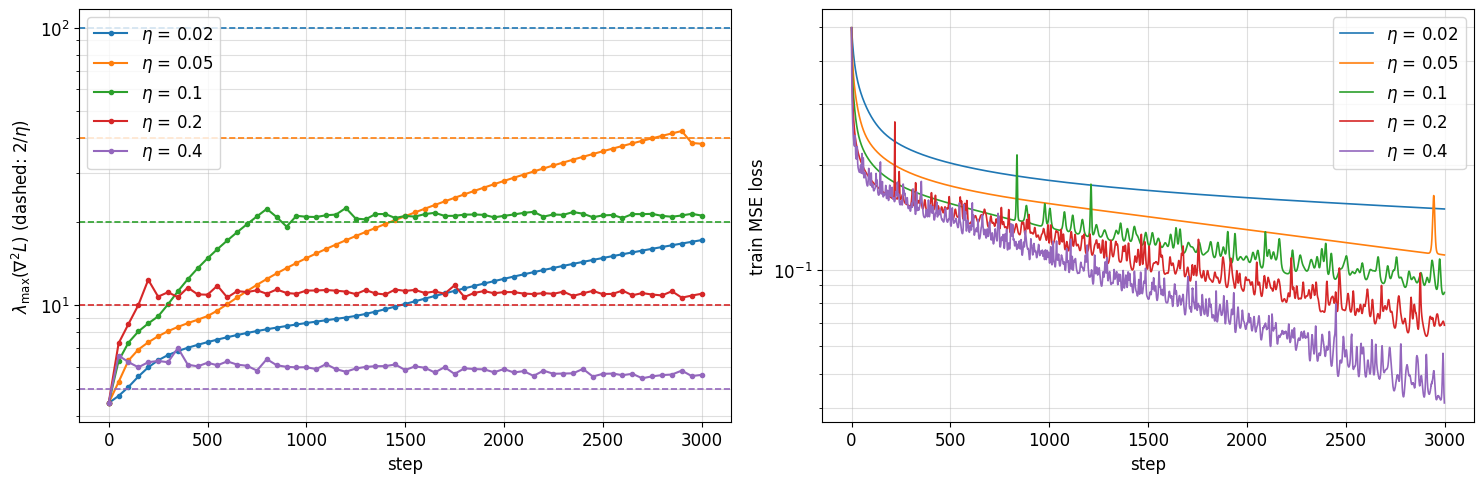

In [71]:
if '7.1' in BONUS_TASKS:
    EOS_LRS = [0.02, 0.05, 0.1, 0.2, 0.4]
    EOS_EVERY = 50
    eos_runs = {}
    for eta in EOS_LRS:
        model = make_tanh_mlp(0)
        params = list(model.parameters())
        optimizer = torch.optim.SGD(params, lr=eta)      # full-batch GD без momentum
        losses, sharp_steps, sharp, v = [], [], [], None
        started = time.perf_counter()
        for step in range(EOS_STEPS + 1):
            if step % EOS_EVERY == 0:
                lam, v = top_eigenvalue(lambda: mse_loss(model), params, iters=20, v=v)
                sharp_steps.append(step)
                sharp.append(lam)
            if step == EOS_STEPS:
                break
            loss = mse_loss(model)
            if not math.isfinite(loss.item()):
                print(f'eta={eta}: divergence at step {step}')
                break
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
        eos_runs[eta] = dict(loss=losses, steps=sharp_steps, sharpness=sharp)
        print(f'eta={eta}: 2/eta = {2 / eta:.1f}; sharpness start {sharp[0]:.2f}, max {max(sharp):.2f}, '
              f'final {sharp[-1]:.2f}; loss {losses[0]:.4f} -> {losses[-1]:.4f}; {time.perf_counter() - started:.0f}s')

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    for i, (eta, run) in enumerate(eos_runs.items()):
        ax1.plot(run['steps'], run['sharpness'], 'o-', color=f'C{i}', markersize=3, label=rf'$\eta$ = {eta}')
        ax1.axhline(2 / eta, color=f'C{i}', linestyle='--', linewidth=1.2)
        ax2.plot(run['loss'], color=f'C{i}', linewidth=1.2, label=rf'$\eta$ = {eta}')
    ax1.set_xlabel('step')
    ax1.set_ylabel(r'$\lambda_{\max}(\nabla^2 L)$ (dashed: $2/\eta$)')
    ax1.set_yscale('log')
    ax2.set_xlabel('step')
    ax2.set_ylabel('train MSE loss')
    ax2.set_yscale('log')
    for ax in (ax1, ax2):
        ax.grid(True, which='both', alpha=0.4)
        ax.legend()
    plt.tight_layout()
    plt.show()


**Вопрос.** В каких прогонах sharpness приблизилась к $2/\eta$? Если выхода на границу не было, укажите это. Сопоставьте изменения sharpness и loss. Почему локальный критерий для фиксированной положительно определённой квадратичной функции не гарантирует такую же динамику нелинейной сети?

**Ответ.** Full-batch GD, MLP 784–200–200–10 с tanh, MSE, 2000 объектов, 3000 шагов, $\lambda_{\max}$ каждые 50 шагов (Lanczos). Во всех прогонах начальная sharpness 4.44, и во всех она сначала растёт (progressive sharpening):

| $\eta$ | $2/\eta$ | max $\lambda_{\max}$ | в конце | loss: старт → конец |
|---|---|---|---|---|
| 0.02 | 100 | 17.2 | 17.2 | 0.497 → 0.149 |
| 0.05 | 40 | 42.4 | 38.2 | 0.497 → 0.110 |
| 0.1 | 20 | 22.4 | 21.0 | 0.497 → 0.086 |
| 0.2 | 10 | 12.3 | 11.0 | 0.497 → 0.069 |
| 0.4 | 5 | 7.0 | 5.6 | 0.497 → 0.041 |

- $\eta = 0.02$: граница $2/\eta = 100$ **не достигнута** — sharpness монотонно растёт до 17, loss убывает гладко и монотонно (обычный стабильный режим).
- $\eta = 0.05$: sharpness растёт почти линейно и доходит до $2/\eta = 40$ только к шагу ≈2850; в этот момент на кривой loss виден резкий всплеск (шаг ≈2950), после чего sharpness отступает до 38 — вход в edge of stability в самом конце бюджета.
- $\eta = 0.1, 0.2, 0.4$: sharpness выходит на $2/\eta$ (примерно к шагу 750, 200 и почти сразу соответственно) и дальше **держится около неё** (21.0 при границе 20, 11.0 при 10, 5.6 при 5) до конца. Loss в этих прогонах немонотонный — с частыми всплесками и «зубцами», — но в среднем продолжает убывать, причём быстрее, чем при малых $\eta$ (финальный loss тем меньше, чем больше $\eta$).

Критерий $\eta < 2/\lambda_{\max}$ выведен для **фиксированной** квадратичной функции: гессиан постоянен, и при $\lambda_{\max} > 2/\eta$ итерации вдоль верхнего собственного вектора экспоненциально расходятся. У нейросети гессиан меняется вдоль траектории, и GD сама влияет на кривизну. Когда sharpness превышает $2/\eta$, начинаются колебания вдоль верхнего собственного направления, а члены третьего порядка в разложении loss толкают параметры в область меньшей кривизны (self-stabilization), и sharpness возвращается к $2/\eta$ вместо расходимости. Локальный квадратичный критерий описывает лишь мгновенную устойчивость в точке, а не динамику невыпуклой функции. Ограничения: один seed, одна архитектура, sharpness меряется раз в 50 шагов (короткие выбросы между замерами не видны), Lanczos на 20 итераций даёт приближённое значение.

## 7.2 Свёртка через FFT со stride, padding и groups (0.5 балла)

Теорема о свёртке: $\mathcal F(x * w) = \mathcal F(x) \cdot \mathcal F(w)$. Детали:

- DFT считает циклическую свёртку — дополняем нулями до $H + k_h - 1$ по высоте и $W + k_w - 1$ по ширине;
- `F.conv2d` — cross-correlation, поэтому ядро переворачивается;
- сумма по входным каналам остаётся суммой в частотной области; с `groups` — только внутри группы;
- padding — `F.pad` входа; stride $s$ — прореживание «valid»-результата $[\,::s,\; ::s\,]$.

Реализуйте `conv2d_fft` (dilation = 1; stride и padding — целые числа) через `torch.fft.rfft2` / `irfft2` и `einsum`.

**Оценивание:** код — 0.4; эксперимент — 0; объяснение — 0.1 балла.

In [72]:
if '7.2' in BONUS_TASKS:
    def conv2d_fft(x, weight, bias=None, stride=1, padding=0, groups=1):
        B, C_in, H, W = x.shape
        C_out, c_g, kh, kw = weight.shape
        x = F.pad(x, (padding, padding, padding, padding))
        H_p, W_p = x.shape[-2:]
        fh, fw = H_p + kh - 1, W_p + kw - 1                   # размер линейной свёртки (без циклического наложения)
        Xf = torch.fft.rfft2(x, s=(fh, fw))                    # (B, C_in, fh, fw//2+1)
        Wf = torch.fft.rfft2(weight.flip(-2, -1), s=(fh, fw))  # cross-correlation = свёртка с перевёрнутым ядром
        Xf = Xf.view(B, groups, c_g, fh, -1)
        Wf = Wf.view(groups, C_out // groups, c_g, fh, -1)
        Yf = torch.einsum('bgchw,gochw->bgohw', Xf, Wf).reshape(B, C_out, fh, -1)   # сумма по каналам внутри группы
        y = torch.fft.irfft2(Yf, s=(fh, fw))
        y = y[..., kh - 1:H_p, kw - 1:W_p]                      # «valid»-часть
        y = y[..., ::stride, ::stride]                          # stride — прореживание
        if bias is not None:
            y = y + bias.view(1, -1, 1, 1)
        return y


In [73]:
if '7.2' in BONUS_TASKS:
    torch.manual_seed(0)
    x = torch.randn(2, 4, 13, 10)
    n_checked = 0
    for k, s, p, g in itertools.product([1, 3, (3, 5)], [1, 2, 3], [0, 1, 2], [1, 2, 4]):
        w, b = torch.randn(8, 4 // g, *pair(k)), torch.randn(8)
        ref = F.conv2d(x, w, b, stride=s, padding=p, groups=g)
        out = conv2d_fft(x, w, b, stride=s, padding=p, groups=g)
        assert out.shape == ref.shape and torch.allclose(out, ref, atol=1e-4), (k, s, p, g)
        n_checked += 1
    n_checked

**Вопрос.** Какую долю посчитанных выходов FFT-свёртка выбрасывает при stride $s$? Когда FFT-свёртка всё равно выгоднее прямой?

**Ответ.** FFT-свёртка считает полную линейную свёртку размера $(H + k - 1) \times (W + k - 1)$, из неё берётся «valid»-часть $(H - k + 1) \times (W - k + 1)$, а при stride $s$ — лишь каждый $s$-й элемент по каждой оси. Значит, даже среди valid-выходов выбрасывается доля $1 - 1/s^2$: 75% при $s = 2$, ≈89% при $s = 3$ (а с учётом краёв полной свёртки — ещё больше). Прямая свёртка/im2col со stride эти позиции просто не считает, а FFT по своей природе вычисляет всё сразу.

FFT-свёртка всё равно выгоднее, когда стоимость прямой $O(C_{\text{in}} C_{\text{out}} HW k^2 / s^2)$ велика: большие ядра ($k \gtrsim 7$–11), большие карты, и когда преобразования переиспользуются — FFT входа делается один раз на все $C_{\text{out}}$, FFT ядра — один раз на весь батч, а в частотной области остаётся поэлементное произведение $O(C_{\text{in}} C_{\text{out}} HW)$, не зависящее от $k$. При малых ядрах ($3\times3$) выигрывают прямая/Winograd-свёртка; при большом stride выгоду FFT можно частично вернуть полифазным разложением (разбить вход на $s^2$ прореженных подсигналов). Открытый тест `conv2d_fft` прошёл на всех 81 комбинациях $k, s, p, g$.

## 7.3 Muon для свёрточных весов (1 балл)

[Muon: An optimizer for hidden layers in neural networks](https://kellerjordan.github.io/posts/muon/), Jordan et al., 2024. Для матричного параметра $W \in \mathbb R^{m \times n}$ с градиентом $G_t$ — так он устроен в `torch.optim.Muon` (momentum через EMA, Nesterov):
$$
B_t = \mu B_{t-1} + (1 - \mu)\, G_t, \qquad U_t = (1 - \mu)\, G_t + \mu B_t, \qquad
W \leftarrow W - \eta \sqrt{\max(1,\, m/n)}\; \mathrm{NS}_5(U_t),
$$
где $\mathrm{NS}_5$ — 5 итераций Ньютона–Шульца, приближающие ортогональный множитель $P Q^\top$ из SVD $U_t = P \Sigma Q^\top$:
$$
X_0 = \frac{U_t}{\|U_t\|_F}, \qquad X_{j+1} = a X_j + b\, (X_j X_j^\top) X_j + c\, (X_j X_j^\top)^2 X_j, \qquad (a, b, c) = (3.4445,\, -4.7750,\, 2.0315)
$$
(если $m > n$, итерации идут для $X^\top$). `torch.optim.Muon` принимает только 2D-параметры, а вес свёртки $(C_{\text{out}}, C_{\text{in}}, k, k)$ — это матрица $C_{\text{out}} \times C_{\text{in}} k^2$ (та же, что в `conv2d_unfold`).

1. Реализуйте `newton_schulz` и `ConvMuon` (без weight decay) для параметров любой размерности $\ge 2$: первая ось — строки, остальные разворачиваются в столбцы. Библиотечный Muon считает итерации в bfloat16, поэтому сравнение с ним — с допуском.
2. Обучите ResNet-20: `ConvMuon` с `MUON_LR` для всех 4D-весов, `MyAdamW` как в `train_cifar` для остального (BN, голова), у обоих cosine schedule, бюджет `EPOCHS`, тот же `set_seed(0)`. Сравните с `history_cifar` из 4.2. Здесь сравниваются два фиксированных training recipe, включая разный weight decay на conv-весах; этот опыт не изолирует влияние одного лишь optimizer и не является общим рейтингом.

**Оценивание:** код — 0.5; эксперимент — 0.3; объяснение — 0.2 балла.

In [74]:
if '7.3' in BONUS_TASKS:
    def newton_schulz(M, steps=5, coeffs=(3.4445, -4.7750, 2.0315)):
        # ваш код
        raise NotImplementedError


    class ConvMuon(torch.optim.Optimizer):
        def __init__(self, params, lr=0.02, momentum=0.95):
            super().__init__(params, dict(lr=lr, momentum=momentum))

        @torch.no_grad()
        def step(self):
            for group in self.param_groups:
                mu = group['momentum']
                for p in group['params']:
                    if p.grad is None:
                        continue
                    # ваш код
                    raise NotImplementedError

In [75]:
if '7.3' in BONUS_TASKS:
    def muon_steps(make_optimizer, shape, steps=5):
        torch.manual_seed(0)
        p = torch.randn(shape, requires_grad=True)
        optimizer = make_optimizer(p)
        gen = torch.Generator().manual_seed(1)
        for _ in range(steps):
            optimizer.zero_grad()
            (p * torch.randn(shape, generator=gen)).sum().backward()
            optimizer.step()
        return p.detach()


    torch.manual_seed(0)
    M = torch.randn(64, 32) * torch.logspace(0, -3, 32)
    assert torch.linalg.svdvals(newton_schulz(M)).max() < 1.3

    for shape in [(48, 20), (20, 48)]:
        start = muon_steps(lambda p: torch.optim.SGD([p], lr=0.0), shape)   # lr = 0: начальная точка
        mine = muon_steps(lambda p: ConvMuon([p], lr=0.02), shape)
        ref = muon_steps(lambda p: torch.optim.Muon([p], lr=0.02, weight_decay=0.0), shape)
        assert ((mine - ref).norm() / (ref - start).norm()) < 0.05, shape

    conv_w = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 8, 3, 3))
    flat = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 72))
    assert torch.allclose(conv_w.view(16, 72), flat, atol=1e-6)

In [76]:
if '7.3' in BONUS_TASKS:
    MUON_LR = 0.02
    # ваш код
    raise NotImplementedError
    hist_adamw = history_cifar
    print(f'{"":<10}{"train loss":>12}{"test acc":>10}')
    for name, hist in [('AdamW', hist_adamw), ('Muon', hist_muon)]:
        print(f'{name:<10}{hist["train_loss"][-1]:>12.4f}{hist["test_acc"][-1]:>10.4f}')

In [77]:
if '7.3' in BONUS_TASKS:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
    for name, hist in [('AdamW', hist_adamw), ('Muon (conv) + AdamW', hist_muon)]:
        epochs_axis = range(1, len(hist['test_acc']) + 1)
        ax1.semilogy(epochs_axis, hist['train_loss'], 'o-', label=name)
        ax2.plot(epochs_axis, hist['test_acc'], 'o-', label=name)
    ax1.set_ylabel('train loss')
    ax2.set_ylabel('test accuracy')
    for ax in (ax1, ax2):
        ax.set_xlabel('epoch')
        ax.grid(True, which='both', alpha=0.4)
        ax.legend()
    plt.tight_layout()
    plt.show()

**Вопрос.** Какой оптимизатор быстрее снижает train loss и какой даёт лучшую test accuracy при том же бюджете? Сколько памяти состояния на параметр у каждого?

**Ответ.** 

## 7.4 $L_0$-атака на $L_\infty$-робастную модель (1 балл)

Ограничение — число изменённых пикселей:
$$
\max_{\|\delta\|_0 \le k,\;\; x + \delta \in [0, 1]^d} L\big(f(x + \delta), y\big).
$$
Линеаризация: пиксель $i$ выгоднее всего довести до 0 или до 1, прирост loss
$$
\mathrm{gain}_i = \max\big(g_i (1 - x_i),\; -g_i\, x_i\big), \qquad g = \nabla_x L.
$$
Жадная атака: $k$ раз пересчитать градиент и изменить ещё не тронутый пиксель с максимальным $\mathrm{gain}_i$ — на 1, если $g_i > 0$, иначе на 0.

1. Используйте готовую `greedy_pixel_attack` из семинара 4 ниже; переписывать её не требуется. Баллы — за эксперимент и интерпретацию.
2. Accuracy от $k$ для стандартной модели и PGD-AT на `XF_test[:500]`.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [78]:
if '7.4' in BONUS_TASKS:
    def greedy_pixel_attack(model, x, y, k):
        x_adv = x.detach().clone()
        changed = torch.zeros_like(x_adv, dtype=torch.bool)
        for _ in range(k):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y, reduction='sum'), x_adv)
            x_adv = x_adv.detach()
            gain = torch.maximum(grad * (1 - x_adv), -grad * x_adv).masked_fill(changed, -float('inf'))
            idx = gain.flatten(1).argmax(dim=1, keepdim=True)
            new_val = (grad.flatten(1).gather(1, idx) > 0).float()
            x_adv = x_adv.flatten(1).scatter(1, idx, new_val).view_as(x)
            changed = changed.flatten(1).scatter(1, idx, True).view_as(x)
        return x_adv

In [79]:
if '7.4' in BONUS_TASKS:
    x, y = XF_test[:500], YF_test[:500]
    x5 = greedy_pixel_attack(model_a, x, y, k=5)
    n_changed = ((x5 - x).flatten(1) != 0).sum(dim=1)
    assert n_changed.max() <= 5 and x5.min() >= 0 and x5.max() <= 1
    assert torch.isin(x5[x5 != x], torch.tensor([0.0, 1.0], device=x.device)).all()
    assert_no_param_grads(model_a)
    print({'clean': attack_accuracy(model_a, x, y), 'L0, k=5': attack_accuracy(model_a, x5, y)})

    ks = [0, 1, 2, 3, 5, 10, 20, 30]
    l0_curves = {name: [attack_accuracy(m, greedy_pixel_attack(m, x, y, k), y) for k in ks]
                 for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
    for name, accs in l0_curves.items():
        print(f'{name:<10}' + ''.join(f'{a:>7.3f}' for a in accs))

{'clean': 0.92, 'L0, k=5': 0.646}
standard    0.920  0.888  0.844  0.766  0.646  0.386  0.128  0.026
PGD-AT      0.854  0.824  0.786  0.772  0.718  0.638  0.426  0.282


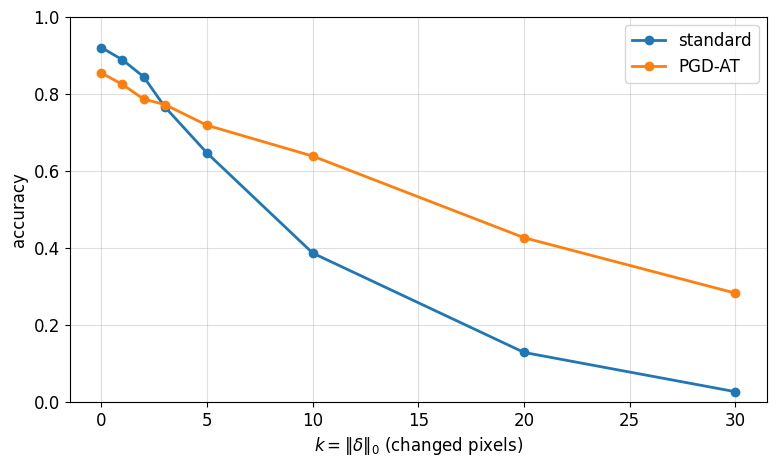

In [80]:
if '7.4' in BONUS_TASKS:
    plt.figure(figsize=(9, 5))
    for name, accs in l0_curves.items():
        plt.plot(ks, accs, 'o-', linewidth=2, label=name)
    plt.xlabel(r'$k = \|\delta\|_0$ (changed pixels)')
    plt.ylabel('accuracy')
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(True, alpha=0.4)
    plt.show()

**Вопрос.** Помогает ли робастность в $L_\infty$ против $L_0$-атаки? Почему $L_\infty$-шар радиуса $\varepsilon$ не защищает от изменения одного пикселя с 0 до 1?

**Ответ.** Жадная $L_0$-атака на `XF_test[:500]`, accuracy по числу изменённых пикселей $k$:

| $k$ | 0 | 1 | 2 | 3 | 5 | 10 | 20 | 30 |
|---|---|---|---|---|---|---|---|---|
| standard | 0.920 | 0.888 | 0.844 | 0.766 | 0.646 | 0.386 | 0.128 | 0.026 |
| PGD-AT | 0.854 | 0.824 | 0.786 | 0.772 | 0.718 | 0.638 | 0.426 | 0.282 |

$L_\infty$-робастность **частично** помогает: с $k = 3$ PGD-AT обгоняет стандартную модель, несмотря на более низкую clean accuracy (0.772 vs 0.766), а дальше разрыв растёт (0.638 vs 0.386 при $k = 10$, 0.282 vs 0.026 при $k = 30$) — accuracy убывает медленнее. Но защиты нет: 30 пикселей (3.8% изображения) снижают accuracy PGD-AT с 0.854 до 0.282, а первые 1–2 пикселя обе модели «съедают» одинаково (−3 и −7 п.п.).

$L_\infty$-шар радиуса $\varepsilon = 0.1$ ограничивает изменение **каждого** пикселя на 0.1, а смена одного пикселя с 0 на 1 даёт $\|\delta\|_\infty = 1$ — в 10 раз дальше границы шара, на котором обучалась модель; adversarial training ничего не обещает за пределами своего threat model. Частичная устойчивость — побочный эффект AT: меньшие и более сосредоточенные на объекте градиенты (6.3), модель меньше опирается на отдельные пиксели фона, поэтому каждый изменённый пиксель даёт меньший прирост loss. Ограничения: 500 объектов (погрешность ≈±2 п.п.); атака жадная и градиентная — более сильная $L_0$-атака (например, Sparse-RS) дала бы ещё ниже accuracy, т.е. эти числа — верхняя оценка робастности.

## 7.5 Catastrophic overfitting (1 балл)

Включается через `'7.5'` в `BONUS_TASKS`; нужны функции из 6.1 и 6.2. Обучите две дополнительные модели с готовыми FGSM и FGSM-RS при `EPS_CO=0.2`. FGSM-RS начинает из случайной точки, делает один шаг размера $1.25\varepsilon$ и проецируется обратно в допустимое множество.

В работе [Wong et al., 2020](https://arxiv.org/pdf/2001.03994) описано catastrophic overfitting: PGD accuracy резко падает, хотя FGSM accuracy остаётся высокой. Random start может помочь, но ни возникновение эффекта за наш бюджет, ни его устранение не гарантированы.

Код обучения и графика дан; баллы — за диагностику и объяснение. Не меняйте эпохи или радиус только ради получения «нужной картинки». Если добавите контрольный опыт, запишите его настройки отдельно.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [81]:
if '7.5' in BONUS_TASKS:
    EPS_CO = 0.2
    co_history = {}
    for name in ['FGSM', 'FGSM-RS']:
        print(name)
        set_seed(0)
        robust[f'{name}, eps={EPS_CO}'] = SmallCNN()
        co_history[name] = adversarial_train(robust[f'{name}, eps={EPS_CO}'], EPS_CO, TRAIN_ATTACKS[name])

FGSM
epoch 1/5  clean 0.740  FGSM 0.637  PGD-20 0.039  3s
epoch 2/5  clean 0.630  FGSM 0.896  PGD-20 0.002  6s
epoch 3/5  clean 0.610  FGSM 0.931  PGD-20 0.001  9s
epoch 4/5  clean 0.678  FGSM 0.965  PGD-20 0.000  12s
epoch 5/5  clean 0.598  FGSM 0.980  PGD-20 0.000  15s
FGSM-RS
epoch 1/5  clean 0.768  FGSM 0.618  PGD-20 0.376  3s
epoch 2/5  clean 0.787  FGSM 0.648  PGD-20 0.396  6s
epoch 3/5  clean 0.793  FGSM 0.705  PGD-20 0.427  9s
epoch 4/5  clean 0.799  FGSM 0.709  PGD-20 0.440  12s
epoch 5/5  clean 0.810  FGSM 0.747  PGD-20 0.372  15s


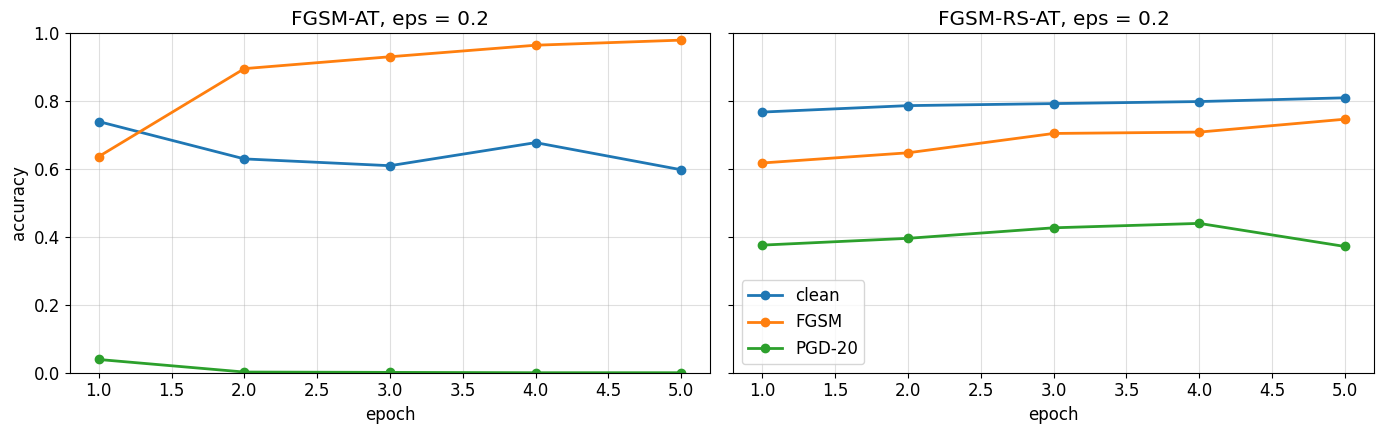

In [82]:
if '7.5' in BONUS_TASKS:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for ax, (name, hist) in zip(axes, co_history.items()):
        epochs_axis = range(1, len(hist['clean']) + 1)
        for key, label in [('clean', 'clean'), ('fgsm', 'FGSM'), ('pgd', 'PGD-20')]:
            ax.plot(epochs_axis, hist[key], 'o-', linewidth=2, label=label)
        ax.set_title(f'{name}-AT, eps = {EPS_CO}')
        ax.set_xlabel('epoch')
        ax.grid(True, alpha=0.4)
    axes[0].set_ylabel('accuracy')
    axes[0].set_ylim(0, 1)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

In [83]:
if '7.5' in BONUS_TASKS:
    co_checks = {name: sanity_checks(robust[f'{name}, eps={EPS_CO}'], XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_CO)
                 for name in ['FGSM', 'FGSM-RS']}
    print(co_checks)

{'FGSM': {'fgsm': 0.62109375, 'pgd20': 0.0, 'pgd100_x5': 0.0, 'eps_1': 0.0}, 'FGSM-RS': {'fgsm': 0.7265625, 'pgd20': 0.359375, 'pgd100_x5': 0.28125, 'eps_1': 0.0}}


**Вопрос.** Был ли резкий спад PGD accuracy и на какой эпохе? Изменил ли картину random start? Сопоставьте динамику FGSM/PGD и результаты усиленной атаки. Если catastrophic overfitting не наблюдается, укажите это и предложите одну проверяемую гипотезу о том, от чего он мог бы зависеть.

**Ответ.** Да, у FGSM-AT при $\varepsilon = 0.2$ catastrophic overfitting наступил **сразу**: PGD-20 accuracy после 1-й эпохи 0.039, после 2-й 0.002, затем 0.001 → 0.000 → 0.000. Одновременно FGSM accuracy растёт 0.637 → 0.896 → 0.931 → 0.965 → **0.980** — выше clean accuracy (0.598 в конце; clean при этом падает с 0.740). Модель «выучила» FGSM-атаку: loss вокруг данных стал сильно нелинейным, и одношаговое линейное приближение указывает в бесполезную сторону, а многошаговый PGD легко находит уязвимость. Усиленная проверка из 6.2 это подтверждает: FGSM 0.621, PGD-20 0.000, PGD-100×5 0.000, $\varepsilon = 1$ → 0 — робастность нулевая, высокая FGSM accuracy — чистый gradient masking.

Random start изменил картину: у FGSM-RS PGD-20 accuracy 0.376 → 0.396 → 0.427 → 0.440 → 0.372, FGSM 0.618 → 0.747, clean 0.768 → 0.810 — коллапса до нуля за 5 эпох нет, и FGSM/PGD растут согласованно (без «FGSM > clean»). Sanity checks: FGSM 0.727, PGD-20 0.359, PGD-100×5 0.281, $\varepsilon = 1$ → 0; усиленная атака снимает ещё 7.8 п.п. — PGD-20 переоценивает робастность этой модели, но она реальна. Настораживает падение PGD 0.440 → 0.372 на последней эпохе: оно больше шума оценки на 1000 объектах (≈±1.5 п.п.) и может быть началом catastrophic overfitting — Wong et al. отмечали, что при больших $\varepsilon$ FGSM-RS тоже может сорваться. **Проверяемая гипотеза:** CO у FGSM-RS зависит от отношения шага к радиусу $\alpha/\varepsilon$ — при тех же эпохах FGSM-RS с $\alpha = 1.0\varepsilon$ останется устойчивым, а с $\alpha = 1.5$–$2\varepsilon$ PGD accuracy обвалится. Контрольные опыты не запускались; эпохи и радиус не менялись.